In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
data = pd.read_csv("LeadScoring MLOPS/Data/Lead Scoring.csv")


In [3]:
data.head()

,Prospect ID,Lead Number,Lead Origin,Lead Source,Do Not Email,Do Not Call,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,...,Get updates on DM Content,Lead Profile,City,Asymmetrique Activity Index,Asymmetrique Profile Index,Asymmetrique Activity Score,Asymmetrique Profile Score,I agree to pay the amount through cheque,A free copy of Mastering The Interview,Last Notable Activity
0,7927b2df-8bba-4d29-b9a2-b6e0beafe620,660737,API,Olark Chat,No,No,0,0.0,0,0.0,...,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Modified
1,2a272436-5132-4136-86fa-dcc88c88f482,660728,API,Organic Search,No,No,0,5.0,674,2.5,...,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Email Opened
2,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,660727,Landing Page Submission,Direct Traffic,No,No,1,2.0,1532,2.0,...,No,Potential Lead,Mumbai,02.Medium,01.High,14.0,20.0,No,Yes,Email Opened
3,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,660719,Landing Page Submission,Direct Traffic,No,No,0,1.0,305,1.0,...,No,Select,Mumbai,02.Medium,01.High,13.0,17.0,No,No,Modified
4,3256f628-e534-4826-9d63-4a8b88782852,660681,Landing Page Submission,Google,No,No,1,2.0,1428,1.0,...,No,Select,Mumbai,02.Medium,01.High,15.0,18.0,No,No,Modified


In [4]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Lead Number,9240.0,617188.435606,23405.995698,579533.0,596484.5,615479.0,637387.25,660737.0
Converted,9240.0,0.385390,0.486714,0.0,0.0,0.0,1.00,1.0
TotalVisits,9103.0,3.445238,4.854853,0.0,1.0,3.0,5.00,251.0
Total Time Spent on Website,9240.0,487.698268,548.021466,0.0,12.0,248.0,936.00,2272.0
Page Views Per Visit,9103.0,2.362820,2.161418,0.0,1.0,2.0,3.00,55.0
Asymmetrique Activity Score,5022.0,14.306252,1.386694,7.0,14.0,14.0,15.00,18.0
Asymmetrique Profile Score,5022.0,16.344883,1.811395,11.0,15.0,16.0,18.00,20.0


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9240 entries, 0 to 9239
Data columns (total 37 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   Prospect ID                                    9240 non-null   object 
 1   Lead Number                                    9240 non-null   int64  
 2   Lead Origin                                    9240 non-null   object 
 3   Lead Source                                    9204 non-null   object 
 4   Do Not Email                                   9240 non-null   object 
 5   Do Not Call                                    9240 non-null   object 
 6   Converted                                      9240 non-null   int64  
 7   TotalVisits                                    9103 non-null   float64
 8   Total Time Spent on Website                    9240 non-null   int64  
 9   Page Views Per Visit                           9103 

In [6]:
missing_values = data.isnull().sum()/len(data)*100
missing_values = missing_values[missing_values>30].reset_index()

In [7]:
for x in data.columns:
    if data[x].isnull().sum()>3000:
        data = data.drop(x,axis=1)




In [8]:
data.isnull().sum()/len(data)

Prospect ID                                      0.000000
Lead Number                                      0.000000
Lead Origin                                      0.000000
Lead Source                                      0.003896
Do Not Email                                     0.000000
Do Not Call                                      0.000000
Converted                                        0.000000
TotalVisits                                      0.014827
Total Time Spent on Website                      0.000000
Page Views Per Visit                             0.014827
Last Activity                                    0.011147
Country                                          0.266342
Specialization                                   0.155628
How did you hear about X Education               0.238853
What is your current occupation                  0.291126
What matters most to you in choosing a course    0.293182
Search                                           0.000000
Magazine      

In [9]:
data['Lead Source'].value_counts()

Lead Source
Google               2868
Direct Traffic       2543
Olark Chat           1755
Organic Search       1154
Reference             534
Welingak Website      142
Referral Sites        125
Facebook               55
bing                    6
google                  5
Click2call              4
Press_Release           2
Social Media            2
Live Chat               2
youtubechannel          1
testone                 1
Pay per Click Ads       1
welearnblog_Home        1
WeLearn                 1
blog                    1
NC_EDM                  1
Name: count, dtype: int64

In [10]:
replacement_dict = {
    "google": "Google",
    "youtubechannel": "Social Media",
    "Facebook": "Social Media",
    "welearnblog_Home": "blog"
}
data['Lead Source'] = data['Lead Source'].replace(replacement_dict)


In [11]:
data['Lead Source'] = data['Lead Source'].fillna('Google')

In [12]:
data['Lead Source'].isnull().sum()

np.int64(0)

In [13]:
data.isnull().sum()

Prospect ID                                         0
Lead Number                                         0
Lead Origin                                         0
Lead Source                                         0
Do Not Email                                        0
Do Not Call                                         0
Converted                                           0
TotalVisits                                       137
Total Time Spent on Website                         0
Page Views Per Visit                              137
Last Activity                                     103
Country                                          2461
Specialization                                   1438
How did you hear about X Education               2207
What is your current occupation                  2690
What matters most to you in choosing a course    2709
Search                                              0
Magazine                                            0
Newspaper Article           

<Axes: ylabel='TotalVisits'>

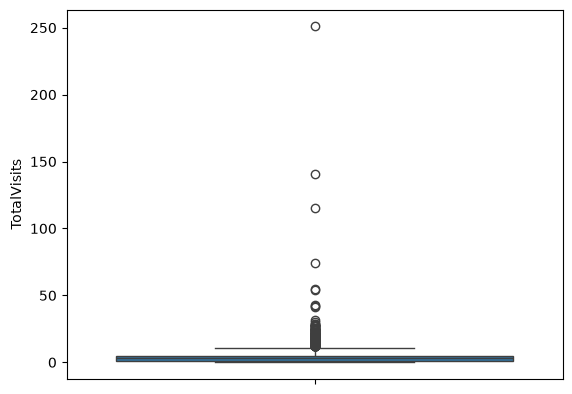

In [14]:
sns.boxplot(data['TotalVisits'])

In [15]:
data['TotalVisits']=data['TotalVisits'].fillna(data['TotalVisits'].mean())

In [16]:
data['TotalVisits'].isnull().sum()

np.int64(0)

<Axes: ylabel='Page Views Per Visit'>

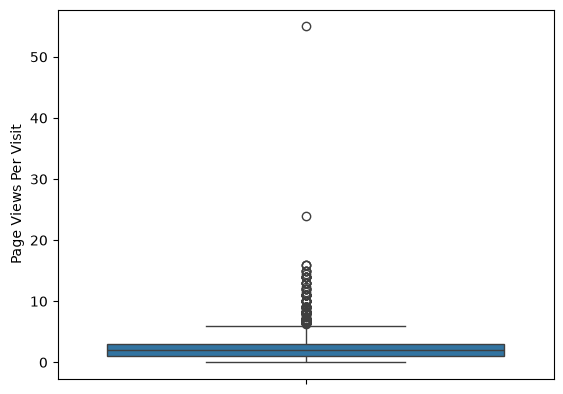

In [17]:
sns.boxplot(data['Page Views Per Visit'])

In [18]:
data['Page Views Per Visit'] = data['Page Views Per Visit'].fillna(data['Page Views Per Visit'].mean())

In [19]:
data['Page Views Per Visit'].isnull().sum()

np.int64(0)

In [20]:
data['Last Activity'].value_counts()

Last Activity
Email Opened                    3437
SMS Sent                        2745
Olark Chat Conversation          973
Page Visited on Website          640
Converted to Lead                428
Email Bounced                    326
Email Link Clicked               267
Form Submitted on Website        116
Unreachable                       93
Unsubscribed                      61
Had a Phone Conversation          30
Approached upfront                 9
View in browser link Clicked       6
Email Received                     2
Email Marked Spam                  2
Visited Booth in Tradeshow         1
Resubscribed to emails             1
Name: count, dtype: int64

In [21]:

data['Last Activity'] = data['Last Activity'].fillna('Not Defined')

In [22]:
data['Last Activity'].value_counts()

Last Activity
Email Opened                    3437
SMS Sent                        2745
Olark Chat Conversation          973
Page Visited on Website          640
Converted to Lead                428
Email Bounced                    326
Email Link Clicked               267
Form Submitted on Website        116
Not Defined                      103
Unreachable                       93
Unsubscribed                      61
Had a Phone Conversation          30
Approached upfront                 9
View in browser link Clicked       6
Email Received                     2
Email Marked Spam                  2
Visited Booth in Tradeshow         1
Resubscribed to emails             1
Name: count, dtype: int64

In [23]:
data.isnull().sum()

Prospect ID                                         0
Lead Number                                         0
Lead Origin                                         0
Lead Source                                         0
Do Not Email                                        0
Do Not Call                                         0
Converted                                           0
TotalVisits                                         0
Total Time Spent on Website                         0
Page Views Per Visit                                0
Last Activity                                       0
Country                                          2461
Specialization                                   1438
How did you hear about X Education               2207
What is your current occupation                  2690
What matters most to you in choosing a course    2709
Search                                              0
Magazine                                            0
Newspaper Article           

In [24]:
data['Country'] = data['Country'].fillna('India')
data['Country'] = data['Country'].replace('Australia', 'Asia/Pacific Region',)

In [25]:
data.isnull().sum()

Prospect ID                                         0
Lead Number                                         0
Lead Origin                                         0
Lead Source                                         0
Do Not Email                                        0
Do Not Call                                         0
Converted                                           0
TotalVisits                                         0
Total Time Spent on Website                         0
Page Views Per Visit                                0
Last Activity                                       0
Country                                             0
Specialization                                   1438
How did you hear about X Education               2207
What is your current occupation                  2690
What matters most to you in choosing a course    2709
Search                                              0
Magazine                                            0
Newspaper Article           

In [26]:
data['How did you hear about X Education'].value_counts()

How did you hear about X Education
Select                   5043
Online Search             808
Word Of Mouth             348
Student of SomeSchool     310
Other                     186
Multiple Sources          152
Advertisements             70
Social Media               67
Email                      26
SMS                        23
Name: count, dtype: int64

In [27]:
data['How did you hear about X Education'] = data['How did you hear about X Education'].replace('Select','Unknown')

In [28]:
data['How did you hear about X Education'] = data['How did you hear about X Education'].fillna('Unknown')

In [29]:
data.isnull().sum()

Prospect ID                                         0
Lead Number                                         0
Lead Origin                                         0
Lead Source                                         0
Do Not Email                                        0
Do Not Call                                         0
Converted                                           0
TotalVisits                                         0
Total Time Spent on Website                         0
Page Views Per Visit                                0
Last Activity                                       0
Country                                             0
Specialization                                   1438
How did you hear about X Education                  0
What is your current occupation                  2690
What matters most to you in choosing a course    2709
Search                                              0
Magazine                                            0
Newspaper Article           

In [30]:
data['Specialization'].value_counts()

Specialization
Select                               1942
Finance Management                    976
Human Resource Management             848
Marketing Management                  838
Operations Management                 503
Business Administration               403
IT Projects Management                366
Supply Chain Management               349
Banking, Investment And Insurance     338
Travel and Tourism                    203
Media and Advertising                 203
International Business                178
Healthcare Management                 159
Hospitality Management                114
E-COMMERCE                            112
Retail Management                     100
Rural and Agribusiness                 73
E-Business                             57
Services Excellence                    40
Name: count, dtype: int64

In [31]:
data['Specialization'] = data['Specialization'].replace('Select','Unknown')

In [32]:
data['Specialization']  = data['Specialization'].fillna('Unknown')

In [33]:
data.isnull().sum()

Prospect ID                                         0
Lead Number                                         0
Lead Origin                                         0
Lead Source                                         0
Do Not Email                                        0
Do Not Call                                         0
Converted                                           0
TotalVisits                                         0
Total Time Spent on Website                         0
Page Views Per Visit                                0
Last Activity                                       0
Country                                             0
Specialization                                      0
How did you hear about X Education                  0
What is your current occupation                  2690
What matters most to you in choosing a course    2709
Search                                              0
Magazine                                            0
Newspaper Article           

In [34]:
data['What is your current occupation'].value_counts()

What is your current occupation
Unemployed              5600
Working Professional     706
Student                  210
Other                     16
Housewife                 10
Businessman                8
Name: count, dtype: int64

In [35]:
data['What is your current occupation']=data['What is your current occupation'].fillna('Unknown')

In [36]:
data['What matters most to you in choosing a course'].value_counts()

What matters most to you in choosing a course
Better Career Prospects      6528
Flexibility & Convenience       2
Other                           1
Name: count, dtype: int64

In [37]:
data.drop('What matters most to you in choosing a course', axis=1,inplace=True)

In [38]:
missing_values = (data.isnull().sum()/len(data)*100).sort_values()
missing_values[missing_values>0]

City            15.367965
Lead Profile    29.318182
dtype: float64

In [39]:
data['City'].isnull().sum()

np.int64(1420)

In [40]:
data['City'].value_counts()

City
Mumbai                         3222
Select                         2249
Thane & Outskirts               752
Other Cities                    686
Other Cities of Maharashtra     457
Other Metro Cities              380
Tier II Cities                   74
Name: count, dtype: int64

In [41]:
data.loc[data['Country'] != 'India', 'City'] = "Other International Cities"

In [42]:
data[data['Country']!='India']['City']


14      Other International Cities
87      Other International Cities
103     Other International Cities
207     Other International Cities
243     Other International Cities
                   ...            
9139    Other International Cities
9173    Other International Cities
9225    Other International Cities
9235    Other International Cities
9239    Other International Cities
Name: City, Length: 287, dtype: object

# EDA

In [43]:
import random
from scipy.stats import norm, skew

In [44]:
def randomcolor():
    r  = random.random()
    b = random.random()
    g = random.random()
    rgb = [r,g,b]
    return rgb




In [45]:
data

,Prospect ID,Lead Number,Lead Origin,Lead Source,Do Not Email,Do Not Call,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,...,Digital Advertisement,Through Recommendations,Receive More Updates About Our Courses,Update me on Supply Chain Content,Get updates on DM Content,Lead Profile,City,I agree to pay the amount through cheque,A free copy of Mastering The Interview,Last Notable Activity
0,7927b2df-8bba-4d29-b9a2-b6e0beafe620,660737,API,Olark Chat,No,No,0,0.0,0,0.00,...,No,No,No,No,No,Select,Select,No,No,Modified
1,2a272436-5132-4136-86fa-dcc88c88f482,660728,API,Organic Search,No,No,0,5.0,674,2.50,...,No,No,No,No,No,Select,Select,No,No,Email Opened
2,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,660727,Landing Page Submission,Direct Traffic,No,No,1,2.0,1532,2.00,...,No,No,No,No,No,Potential Lead,Mumbai,No,Yes,Email Opened
3,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,660719,Landing Page Submission,Direct Traffic,No,No,0,1.0,305,1.00,...,No,No,No,No,No,Select,Mumbai,No,No,Modified
4,3256f628-e534-4826-9d63-4a8b88782852,660681,Landing Page Submission,Google,No,No,1,2.0,1428,1.00,...,No,No,No,No,No,Select,Mumbai,No,No,Modified
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9235,19d6451e-fcd6-407c-b83b-48e1af805ea9,579564,Landing Page Submission,Direct Traffic,Yes,No,1,8.0,1845,2.67,...,No,No,No,No,No,Potential Lead,Other International Cities,No,No,Email Marked Spam
9236,82a7005b-7196-4d56-95ce-a79f937a158d,579546,Landing Page Submission,Direct Traffic,No,No,0,2.0,238,2.00,...,No,No,No,No,No,Potential Lead,Mumbai,No,Yes,SMS Sent
9237,aac550fe-a586-452d-8d3c-f1b62c94e02c,579545,Landing Page Submission,Direct Traffic,Yes,No,0,2.0,199,2.00,...,No,No,No,No,No,Potential Lead,Mumbai,No,Yes,SMS Sent
9238,5330a7d1-2f2b-4df4-85d6-64ca2f6b95b9,579538,Landing Page Submission,Google,No,No,1,3.0,499,3.00,...,No,No,No,No,No,NaN,Other Metro Cities,No,No,SMS Sent


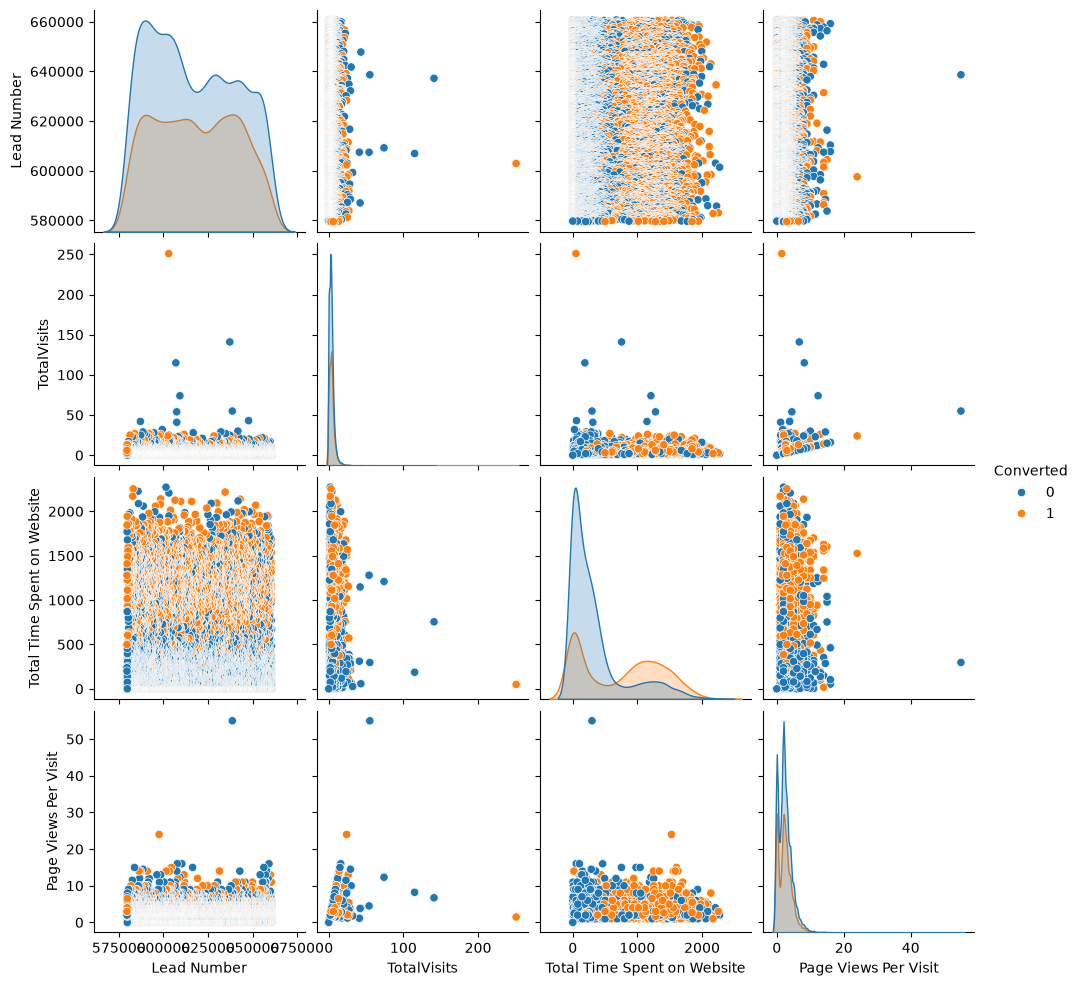

In [46]:
sns.pairplot(data,diag_kind='kde', hue = 'Converted')

<Axes: >

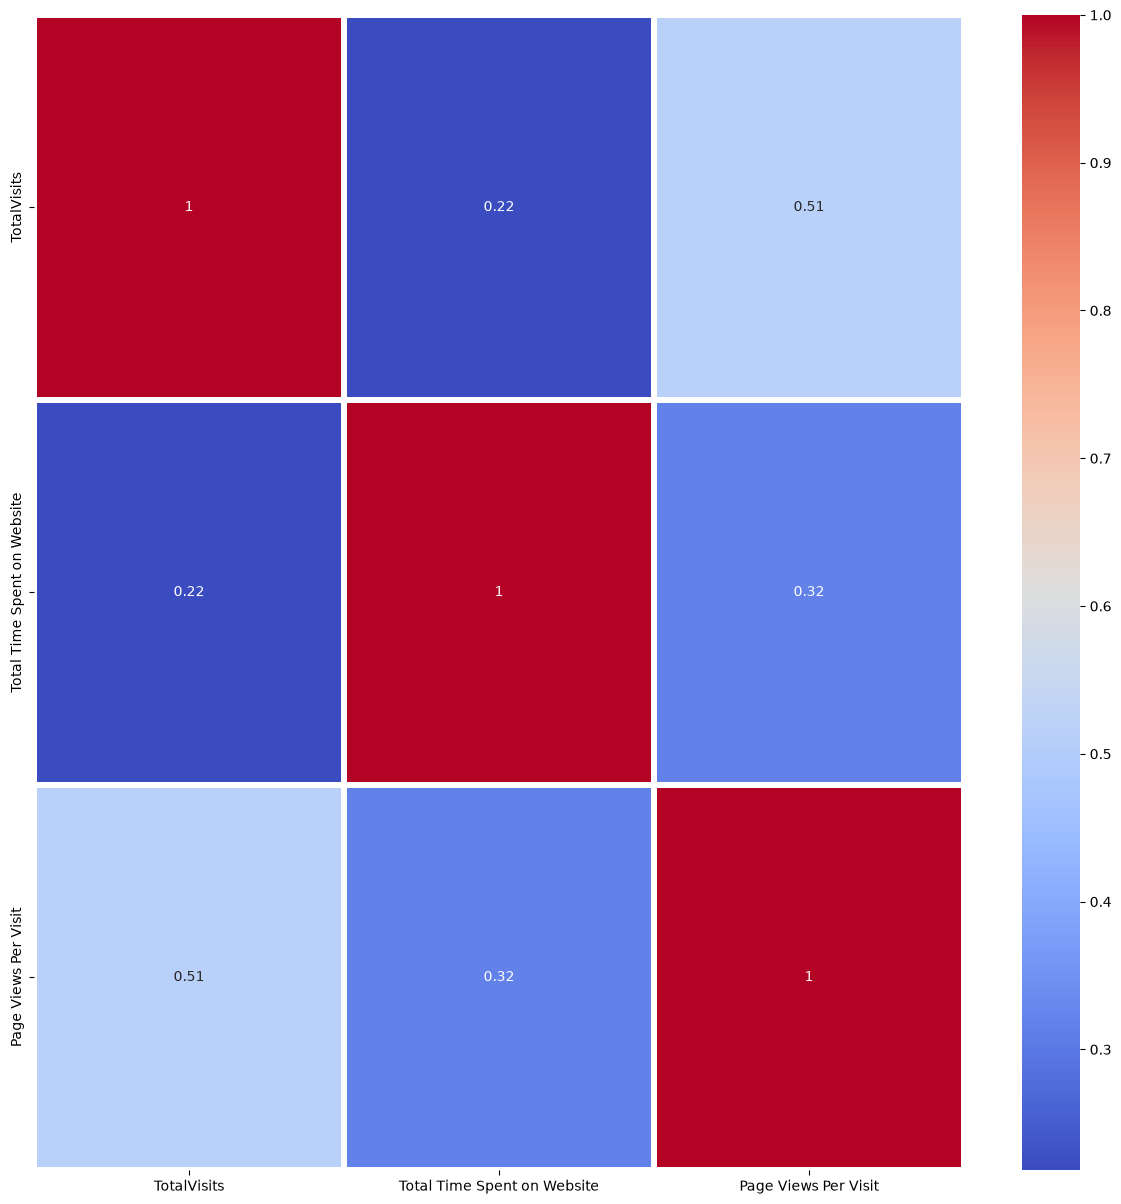

In [47]:
plt.figure(figsize=(15,15))


## calculate correlation matrix
corr_matrics = data[['TotalVisits', 'Total Time Spent on Website', 'Page Views Per Visit']].corr()
sns.heatmap(corr_matrics,annot=True, cmap = 'coolwarm',linewidths=3)

In [48]:
## there is no much correlation so we can move without dropping anything


### Univariate analysis of numerical variables¶


<Figure size 2500x2500 with 0 Axes>

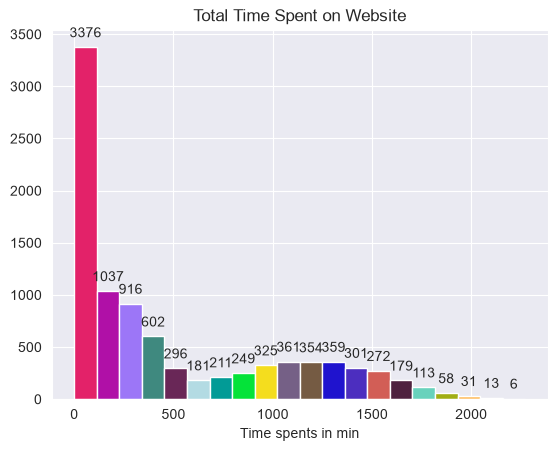

In [49]:
plt.figure(figsize=(25,25))
sns.set_style('darkgrid')
fig, ax = plt.subplots()
N, bins, patches = ax.hist(data['Total Time Spent on Website'], bins=20)
for i in range(20):
    patches[i].set_facecolor(randomcolor())
ax.bar_label(patches, padding=5)
plt.title('Total Time Spent on Website')
ax.set_xlabel('Time spents in min')

plt.show()

/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T/ipykernel_77079/3475762398.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data['Total Time Spent on Website'],fit = norm, color = randomcolor())


Text(0.5, 1.0, 'Distribution Graph of Total Time Spent on Website and skewness is 0.9562949180624318')

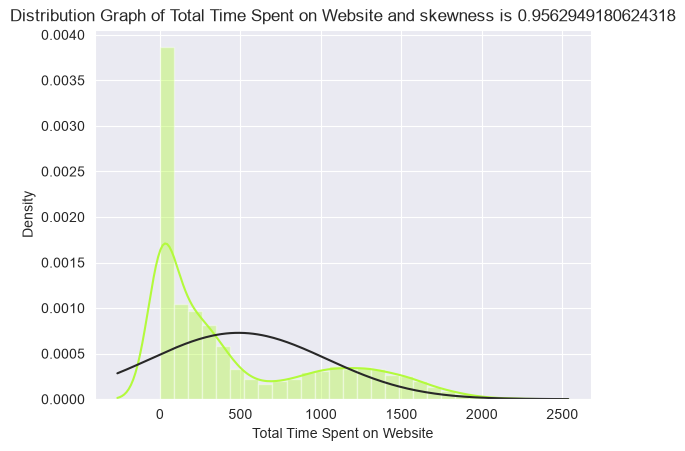

In [50]:
skewness_TTS = str(skew(data['Total Time Spent on Website']))
sns.distplot(data['Total Time Spent on Website'],fit = norm, color = randomcolor())
plt.title(f'Distribution Graph of Total Time Spent on Website and skewness is {skewness_TTS }')

/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T/ipykernel_77079/1146290320.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data['TotalVisits'],fit = norm, color = randomcolor())


Text(0.5, 1.0, 'Distribution Graph of TotalVisits and skewness is 20.05762703774053')

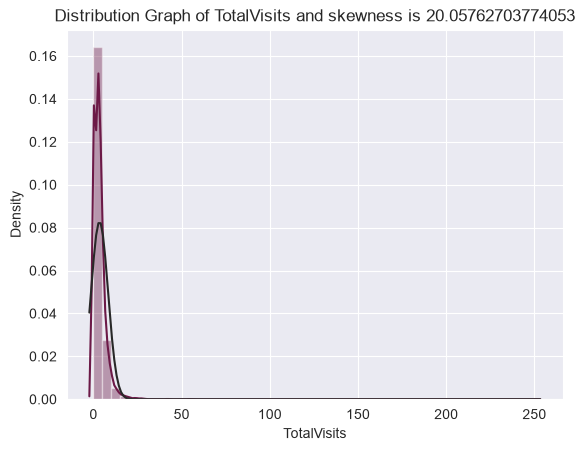

In [51]:
skewness_TV = str(skew(data['TotalVisits']))
sns.distplot(data['TotalVisits'],fit = norm, color = randomcolor())
plt.title(f'Distribution Graph of TotalVisits and skewness is {skewness_TV }')

/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T/ipykernel_77079/915886335.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data['Page Views Per Visit'],fit = norm, color = randomcolor())


Text(0.5, 1.0, 'Distribution Graph of Page Views Per Visit and skewness is 2.892845626319874')

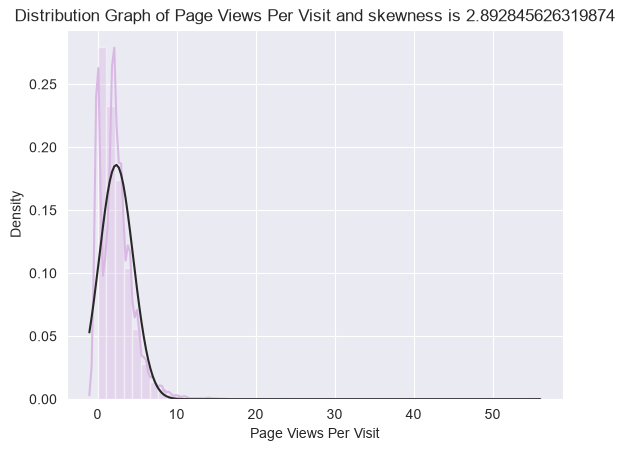

In [52]:
skewness_PVPV = str(skew(data['Page Views Per Visit']))
sns.distplot(data['Page Views Per Visit'],fit = norm, color = randomcolor())
plt.title(f'Distribution Graph of Page Views Per Visit and skewness is {skewness_PVPV }')

/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T/ipykernel_77079/234332677.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data['Page Views Per Visit SQRT'],fit = norm, color = randomcolor())


Text(0.5, 1.0, 'Distribution Graph of Page Views Per Visit SQRT and skewness is -0.2793449084578924')

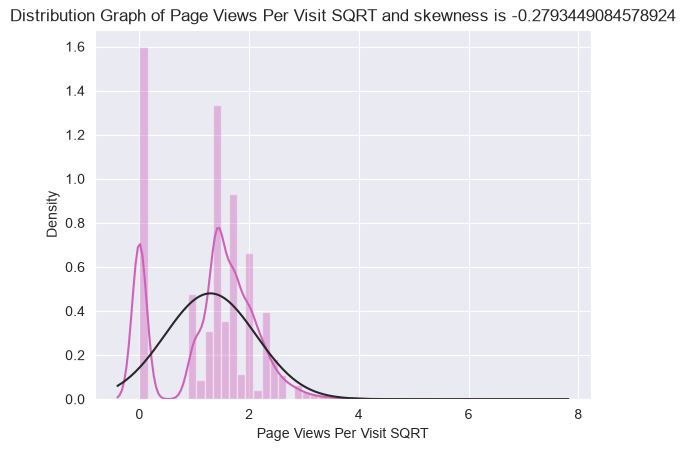

In [53]:
data['Page Views Per Visit SQRT'] = np.sqrt(data['Page Views Per Visit'])
skewness_PVPV = str(skew(data['Page Views Per Visit SQRT']))
sns.distplot(data['Page Views Per Visit SQRT'],fit = norm, color = randomcolor())
plt.title(f'Distribution Graph of Page Views Per Visit SQRT and skewness is {skewness_PVPV }')

/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T/ipykernel_77079/2084739914.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data['TotalVisits SQRT'],fit = norm, color = randomcolor())


Text(0.5, 1.0, 'Distribution Graph of TotalVisits SQRT and skewness is 0.5213091629380514')

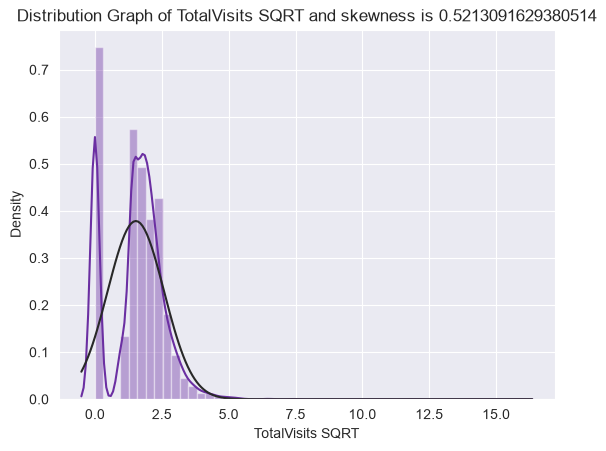

In [54]:
data['TotalVisits SQRT'] = np.sqrt(data['TotalVisits'])
skewness_TV = str(skew(data['TotalVisits SQRT']))
sns.distplot(data['TotalVisits SQRT'],fit = norm, color = randomcolor())
plt.title(f'Distribution Graph of TotalVisits SQRT and skewness is {skewness_TV }')

/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T/ipykernel_77079/3026883684.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data['Total Time Spent on Website SQRT'],fit = norm, color = randomcolor())


Text(0.5, 1.0, 'Distribution Graph of Total Time Spent on Website SQRT and skewness is 0.24932432045706499')

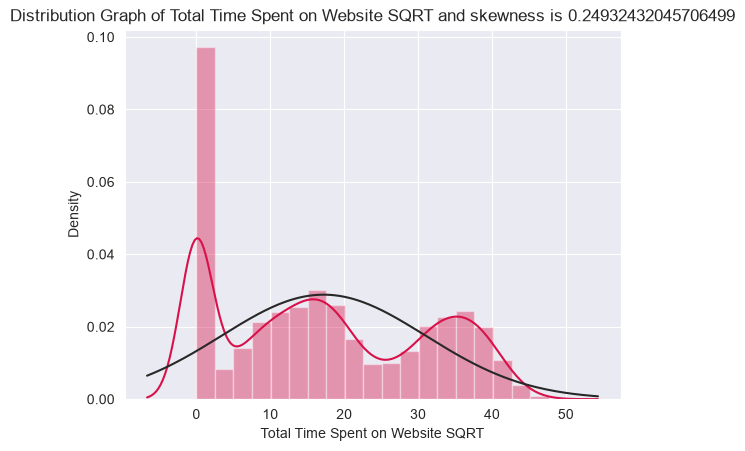

In [55]:
data['Total Time Spent on Website SQRT'] = np.sqrt(data['Total Time Spent on Website'])
skewness_TTSW = str(skew(data['Total Time Spent on Website SQRT']))
sns.distplot(data['Total Time Spent on Website SQRT'],fit = norm, color = randomcolor())
plt.title(f'Distribution Graph of Total Time Spent on Website SQRT and skewness is {skewness_TTSW }')

In [56]:
del data ['Page Views Per Visit']
del data['Total Time Spent on Website']
del data['TotalVisits']

## Categorical variable Analysis

In [57]:
categorical_variables = data.select_dtypes('object')

In [58]:
categorical_variables.columns

Index(['Prospect ID', 'Lead Origin', 'Lead Source', 'Do Not Email',
       'Do Not Call', 'Last Activity', 'Country', 'Specialization',
       'How did you hear about X Education', 'What is your current occupation',
       'Search', 'Magazine', 'Newspaper Article', 'X Education Forums',
       'Newspaper', 'Digital Advertisement', 'Through Recommendations',
       'Receive More Updates About Our Courses',
       'Update me on Supply Chain Content', 'Get updates on DM Content',
       'Lead Profile', 'City', 'I agree to pay the amount through cheque',
       'A free copy of Mastering The Interview', 'Last Notable Activity'],
      dtype='object')

In [59]:
##categorical_variables.drop('Search', inplace=True)

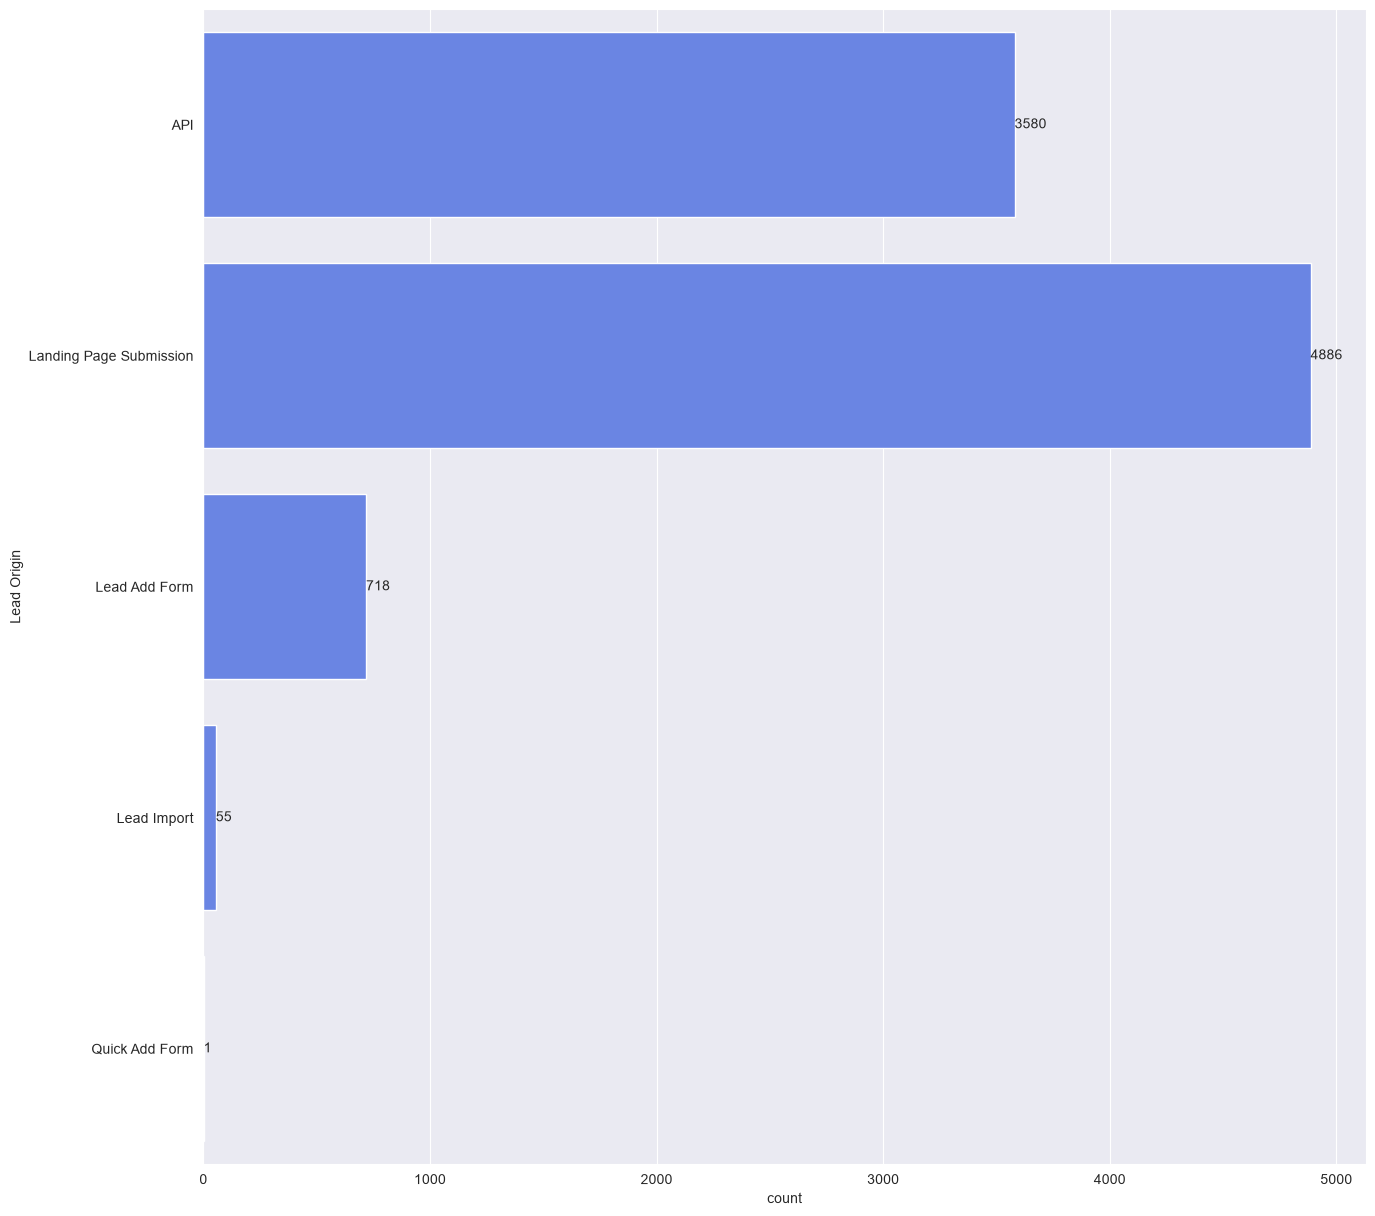

In [60]:
plt.figure(figsize=(15,15))
ax = sns.countplot(data['Lead Origin'], color=randomcolor())
ax.bar_label(ax.containers[0])

plt.show()

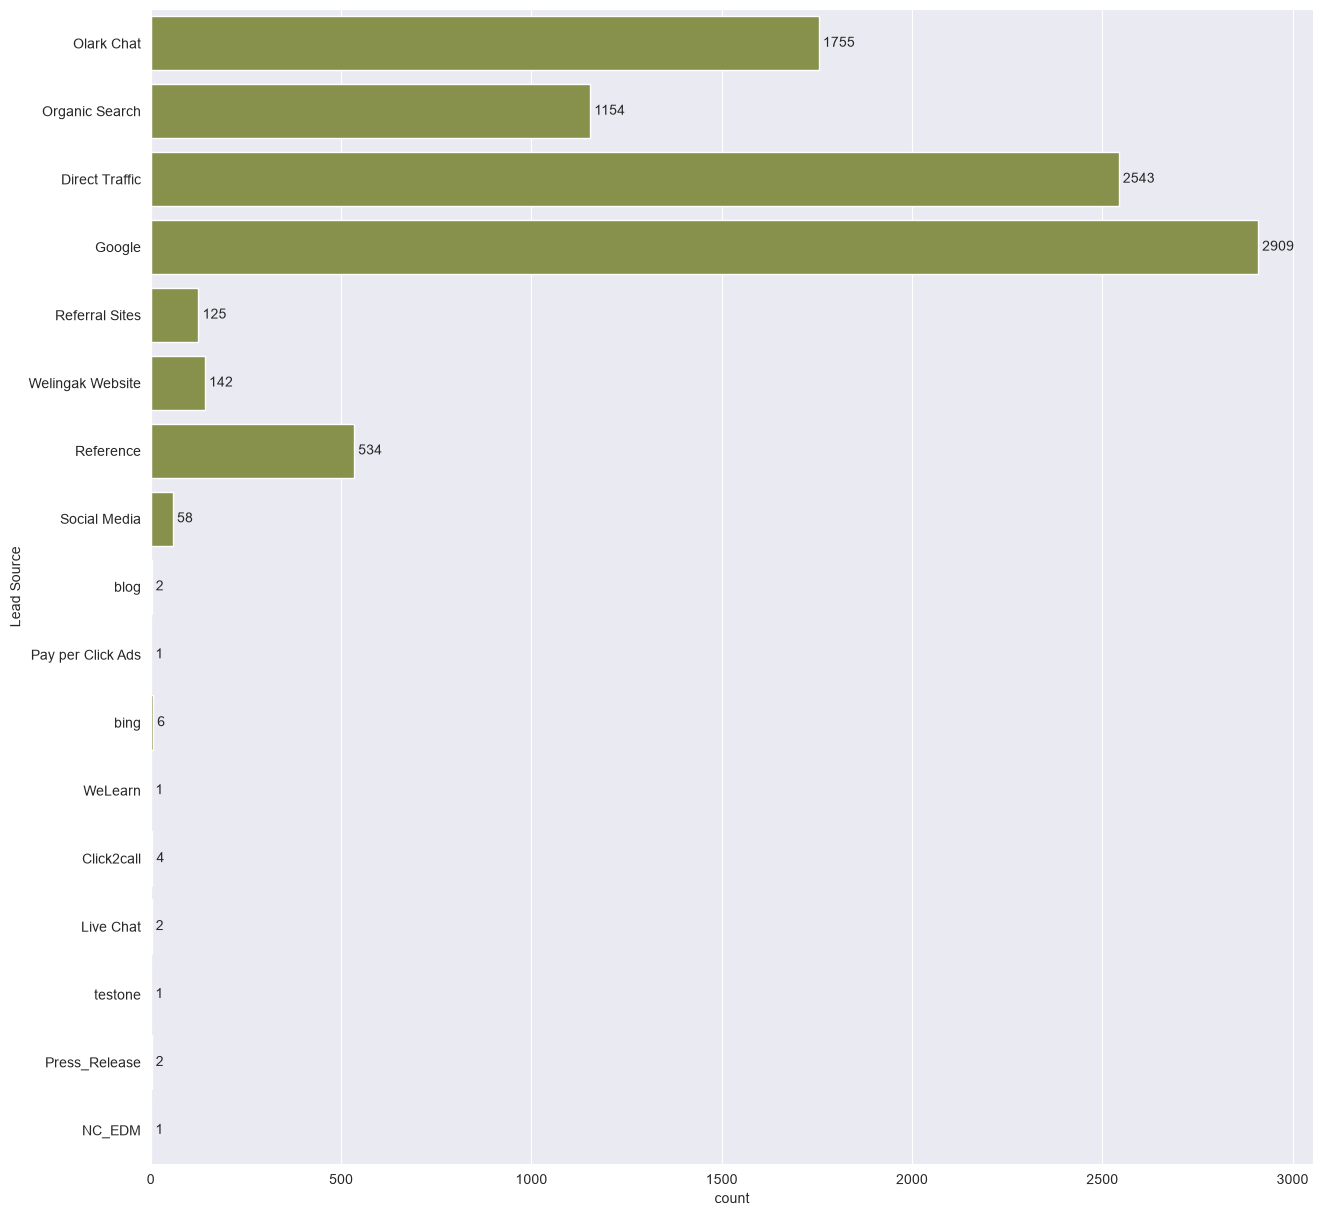

In [61]:
plt.figure(figsize=(15,15))
ax = sns.countplot(data['Lead Source'], color=randomcolor())
ax.bar_label(ax.containers[0], padding=3)

plt.show()

Identifying Outliers

<Axes: ylabel='Total Time Spent on Website SQRT'>

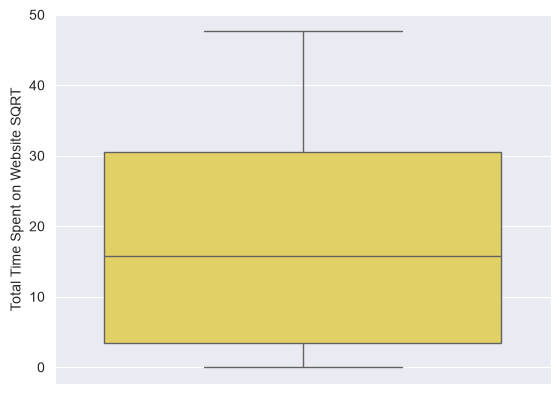

In [62]:
sns.boxplot(data['Total Time Spent on Website SQRT'], color=randomcolor())


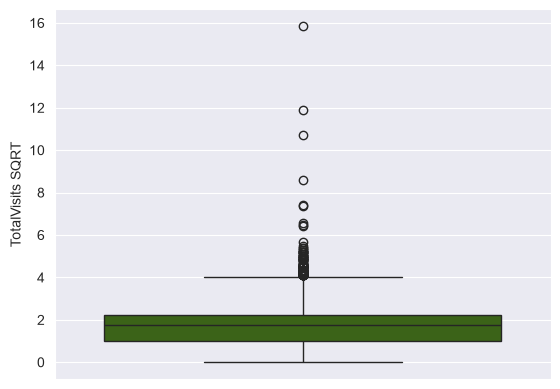

In [63]:
sns.boxplot(data['TotalVisits SQRT'], color=randomcolor())
plt.show()

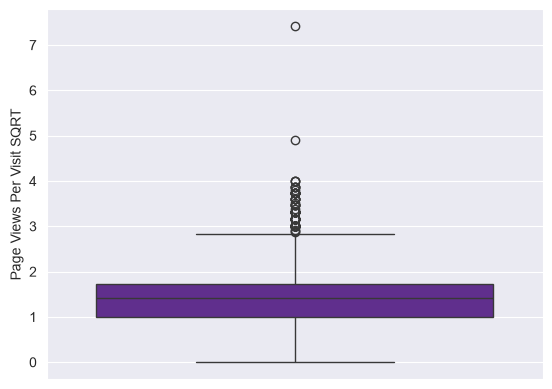

In [64]:
sns.boxplot(data['Page Views Per Visit SQRT'], color=randomcolor())
plt.show()

In [65]:
### we can see the outliers there so try to solve that 
out_num_leads=data[['Page Views Per Visit SQRT','TotalVisits SQRT']]
other_leads = pd.concat([data.select_dtypes(include=['object']),data['Total Time Spent on Website SQRT']],axis =1)
other_leads = pd.concat([other_leads,data["Lead Number"],data['Converted']],axis = 1)



In [66]:
q = out_num_leads.quantile(0.997)
out_num_leads = out_num_leads[out_num_leads<q]
out_num_leads.isnull().sum()


Page Views Per Visit SQRT    31
TotalVisits SQRT             32
dtype: int64

In [67]:
out_num_leads['Page Views Per Visit SQRT'] = out_num_leads['Page Views Per Visit SQRT'].fillna(out_num_leads['Page Views Per Visit SQRT'].median())
out_num_leads['TotalVisits SQRT'] = out_num_leads['TotalVisits SQRT'].fillna(out_num_leads['TotalVisits SQRT'].median())




In [68]:
out_num_leads

,Page Views Per Visit SQRT,TotalVisits SQRT
0,0.000000,0.000000
1,1.581139,2.236068
2,1.414214,1.414214
3,1.000000,1.000000
4,1.000000,1.414214
...,...,...
9235,1.634013,2.828427
9236,1.414214,1.414214
9237,1.414214,1.414214
9238,1.732051,1.732051


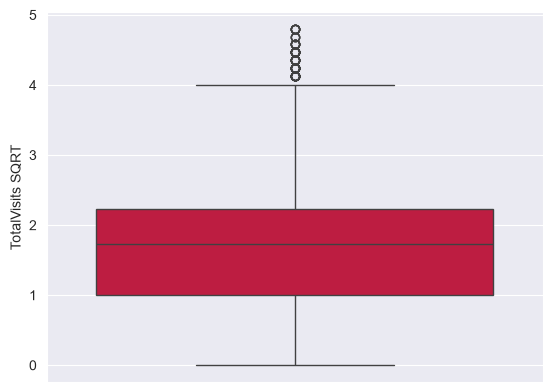

In [69]:
sns.boxplot(out_num_leads['TotalVisits SQRT'],color=randomcolor())
plt.show()

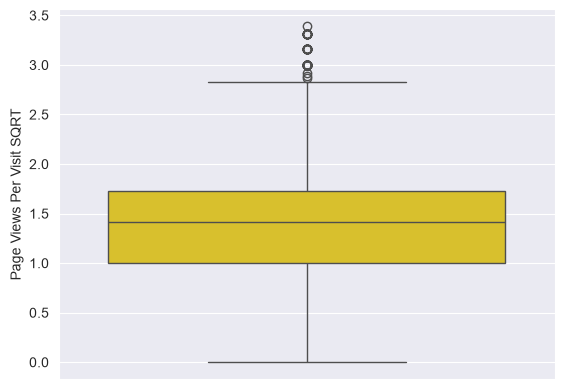

In [70]:
sns.boxplot(out_num_leads['Page Views Per Visit SQRT'],color=randomcolor())
plt.show()

In [71]:
### still we can see few outliers so appaly again 

In [72]:
q = out_num_leads.quantile(0.997)
out_num_leads = out_num_leads[out_num_leads<q]
out_num_leads.isnull().sum()


Page Views Per Visit SQRT    44
TotalVisits SQRT             36
dtype: int64

In [73]:
out_num_leads['Page Views Per Visit SQRT'] = out_num_leads['Page Views Per Visit SQRT'].fillna(out_num_leads['Page Views Per Visit SQRT'].median())
out_num_leads['TotalVisits SQRT'] = out_num_leads['TotalVisits SQRT'].fillna(out_num_leads['TotalVisits SQRT'].median())




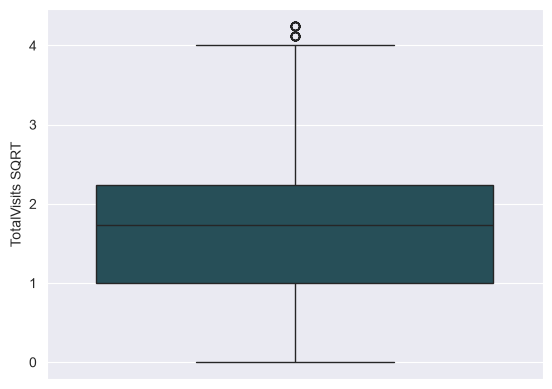

In [74]:
sns.boxplot(out_num_leads['TotalVisits SQRT'],color=randomcolor())
plt.show()

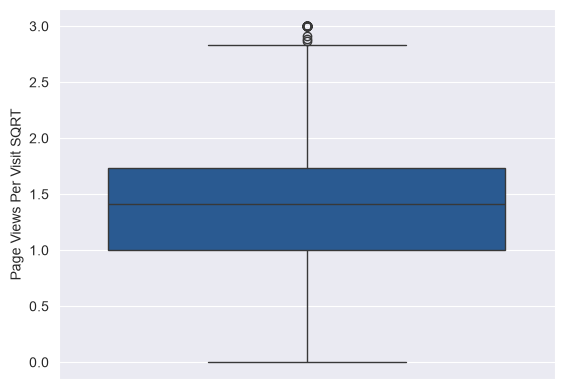

In [75]:
sns.boxplot(out_num_leads['Page Views Per Visit SQRT'],color=randomcolor())
plt.show()

In [76]:
out_num_leads['Page Views Per Visit SQRT'] = out_num_leads['Page Views Per Visit SQRT'].fillna(out_num_leads['Page Views Per Visit SQRT'].median())
out_num_leads['TotalVisits SQRT'] = out_num_leads['TotalVisits SQRT'].fillna(out_num_leads['TotalVisits SQRT'].median())




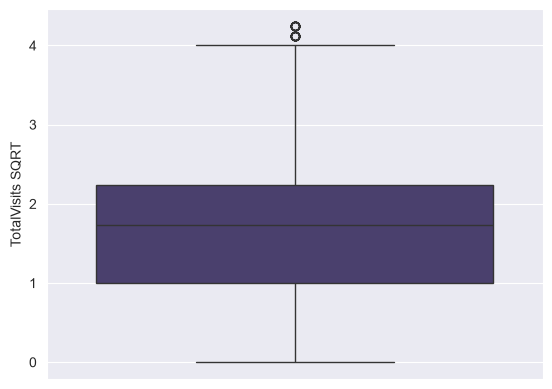

In [77]:
sns.boxplot(out_num_leads['TotalVisits SQRT'],color=randomcolor())
plt.show()

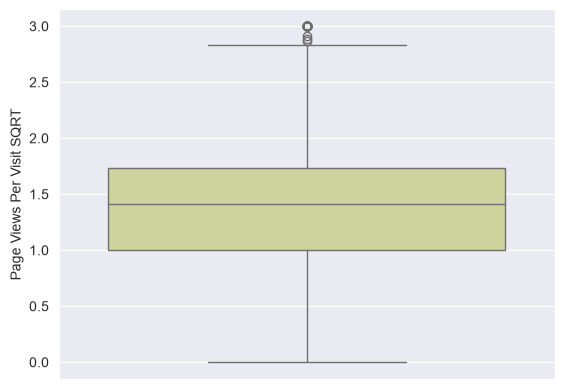

In [78]:
sns.boxplot(out_num_leads['Page Views Per Visit SQRT'],color=randomcolor())
plt.show()

In [79]:

cleaned_leads = pd.concat([out_num_leads, other_leads], axis=1)

In [80]:
other_leads

,Prospect ID,Lead Origin,Lead Source,Do Not Email,Do Not Call,Last Activity,Country,Specialization,How did you hear about X Education,What is your current occupation,...,Update me on Supply Chain Content,Get updates on DM Content,Lead Profile,City,I agree to pay the amount through cheque,A free copy of Mastering The Interview,Last Notable Activity,Total Time Spent on Website SQRT,Lead Number,Converted
0,7927b2df-8bba-4d29-b9a2-b6e0beafe620,API,Olark Chat,No,No,Page Visited on Website,India,Unknown,Unknown,Unemployed,...,No,No,Select,Select,No,No,Modified,0.000000,660737,0
1,2a272436-5132-4136-86fa-dcc88c88f482,API,Organic Search,No,No,Email Opened,India,Unknown,Unknown,Unemployed,...,No,No,Select,Select,No,No,Email Opened,25.961510,660728,0
2,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,Landing Page Submission,Direct Traffic,No,No,Email Opened,India,Business Administration,Unknown,Student,...,No,No,Potential Lead,Mumbai,No,Yes,Email Opened,39.140772,660727,1
3,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,Landing Page Submission,Direct Traffic,No,No,Unreachable,India,Media and Advertising,Word Of Mouth,Unemployed,...,No,No,Select,Mumbai,No,No,Modified,17.464249,660719,0
4,3256f628-e534-4826-9d63-4a8b88782852,Landing Page Submission,Google,No,No,Converted to Lead,India,Unknown,Other,Unemployed,...,No,No,Select,Mumbai,No,No,Modified,37.788887,660681,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9235,19d6451e-fcd6-407c-b83b-48e1af805ea9,Landing Page Submission,Direct Traffic,Yes,No,Email Marked Spam,Saudi Arabia,IT Projects Management,Unknown,Unemployed,...,No,No,Potential Lead,Other International Cities,No,No,Email Marked Spam,42.953463,579564,1
9236,82a7005b-7196-4d56-95ce-a79f937a158d,Landing Page Submission,Direct Traffic,No,No,SMS Sent,India,Media and Advertising,Unknown,Unemployed,...,No,No,Potential Lead,Mumbai,No,Yes,SMS Sent,15.427249,579546,0
9237,aac550fe-a586-452d-8d3c-f1b62c94e02c,Landing Page Submission,Direct Traffic,Yes,No,SMS Sent,India,Business Administration,Unknown,Unemployed,...,No,No,Potential Lead,Mumbai,No,Yes,SMS Sent,14.106736,579545,0
9238,5330a7d1-2f2b-4df4-85d6-64ca2f6b95b9,Landing Page Submission,Google,No,No,SMS Sent,India,Human Resource Management,Online Search,Unknown,...,No,No,NaN,Other Metro Cities,No,No,SMS Sent,22.338308,579538,1


# Data Preparation Stage

In [81]:
from sklearn.preprocessing import OneHotEncoder

In [82]:
cleaned_leads = cleaned_leads.drop('I agree to pay the amount through cheque', axis=1)

In [83]:
cleaned_leads = cleaned_leads.drop('Get updates on DM Content', axis=1)

In [84]:
cleaned_leads = cleaned_leads.drop('Update me on Supply Chain Content', axis=1)

In [85]:
cleaned_leads = cleaned_leads.drop('Receive More Updates About Our Courses', axis=1)

In [86]:
cleaned_leads = cleaned_leads.drop('Search', axis=1)
cleaned_leads = cleaned_leads.drop('Magazine', axis=1)
cleaned_leads = cleaned_leads.drop('Newspaper Article', axis=1)
cleaned_leads = cleaned_leads.drop('X Education Forums', axis=1)
cleaned_leads = cleaned_leads.drop('Newspaper', axis=1)
cleaned_leads = cleaned_leads.drop('Digital Advertisement', axis=1)


In [ ]:
cleaned_leads = cleaned_leads.drop('Do Not Call', axis=1)


In [89]:
encoding_variables = cleaned_leads.drop('Prospect ID', axis=1).select_dtypes(include='object')

NameError: name 'encoding_variables' is not defined

In [90]:
encoding_variables['Lead Profile'] = encoding_variables['Lead Profile'].fillna('Unknown')

In [91]:
encoding_variables['Lead Profile'] = encoding_variables['Lead Profile'].fillna('Unknown')

In [92]:
encoding_variables.isnull().sum()
encoding_variables['Lead Profile'].value_counts()

Lead Profile
Select                         4146
Unknown                        2709
Potential Lead                 1613
Other Leads                     487
Student of SomeSchool           241
Lateral Student                  24
Dual Specialization Student      20
Name: count, dtype: int64

In [93]:
encoding_variables['City'] = encoding_variables['City'].replace('Select','Unknown')
encoding_variables['City']=encoding_variables['City'].fillna("Unknown")


In [94]:

encoding_variables.loc[encoding_variables['Country'] != 'India', 'City'] = "Other International Cities"

In [95]:
encoding_variables.isnull().sum()

Lead Origin                               0
Lead Source                               0
Do Not Email                              0
Last Activity                             0
Country                                   0
Specialization                            0
How did you hear about X Education        0
What is your current occupation           0
Through Recommendations                   0
Lead Profile                              0
City                                      0
A free copy of Mastering The Interview    0
Last Notable Activity                     0
dtype: int64

In [96]:
encoding_variables

,Lead Origin,Lead Source,Do Not Email,Last Activity,Country,Specialization,How did you hear about X Education,What is your current occupation,Through Recommendations,Lead Profile,City,A free copy of Mastering The Interview,Last Notable Activity
0,API,Olark Chat,No,Page Visited on Website,India,Unknown,Unknown,Unemployed,No,Select,Unknown,No,Modified
1,API,Organic Search,No,Email Opened,India,Unknown,Unknown,Unemployed,No,Select,Unknown,No,Email Opened
2,Landing Page Submission,Direct Traffic,No,Email Opened,India,Business Administration,Unknown,Student,No,Potential Lead,Mumbai,Yes,Email Opened
3,Landing Page Submission,Direct Traffic,No,Unreachable,India,Media and Advertising,Word Of Mouth,Unemployed,No,Select,Mumbai,No,Modified
4,Landing Page Submission,Google,No,Converted to Lead,India,Unknown,Other,Unemployed,No,Select,Mumbai,No,Modified
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9235,Landing Page Submission,Direct Traffic,Yes,Email Marked Spam,Saudi Arabia,IT Projects Management,Unknown,Unemployed,No,Potential Lead,Other International Cities,No,Email Marked Spam
9236,Landing Page Submission,Direct Traffic,No,SMS Sent,India,Media and Advertising,Unknown,Unemployed,No,Potential Lead,Mumbai,Yes,SMS Sent
9237,Landing Page Submission,Direct Traffic,Yes,SMS Sent,India,Business Administration,Unknown,Unemployed,No,Potential Lead,Mumbai,Yes,SMS Sent
9238,Landing Page Submission,Google,No,SMS Sent,India,Human Resource Management,Online Search,Unknown,No,Unknown,Other Metro Cities,No,SMS Sent


In [97]:
dummies = pd.get_dummies(encoding_variables, dtype=int)
dummies

,Lead Origin_API,Lead Origin_Landing Page Submission,Lead Origin_Lead Add Form,Lead Origin_Lead Import,Lead Origin_Quick Add Form,Lead Source_Click2call,Lead Source_Direct Traffic,Lead Source_Google,Lead Source_Live Chat,Lead Source_NC_EDM,...,Last Notable Activity_Form Submitted on Website,Last Notable Activity_Had a Phone Conversation,Last Notable Activity_Modified,Last Notable Activity_Olark Chat Conversation,Last Notable Activity_Page Visited on Website,Last Notable Activity_Resubscribed to emails,Last Notable Activity_SMS Sent,Last Notable Activity_Unreachable,Last Notable Activity_Unsubscribed,Last Notable Activity_View in browser link Clicked
0,1,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,1,0,0,0,0,1,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4,0,1,0,0,0,0,0,1,0,0,...,0,0,1,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9235,0,1,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9236,0,1,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,1,0,0,0
9237,0,1,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,1,0,0,0
9238,0,1,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,0


In [98]:

cleaned_leads_dummyfied = pd.concat([cleaned_leads, dummies],axis=1)

for i in encoding_variables:
    del cleaned_leads_dummyfied[i]


In [99]:
cleaned_leads

,Page Views Per Visit SQRT,TotalVisits SQRT,Prospect ID,Lead Origin,Lead Source,Do Not Email,Last Activity,Country,Specialization,How did you hear about X Education,What is your current occupation,Through Recommendations,Lead Profile,City,A free copy of Mastering The Interview,Last Notable Activity,Total Time Spent on Website SQRT,Lead Number,Converted
0,0.000000,0.000000,7927b2df-8bba-4d29-b9a2-b6e0beafe620,API,Olark Chat,No,Page Visited on Website,India,Unknown,Unknown,Unemployed,No,Select,Select,No,Modified,0.000000,660737,0
1,1.581139,2.236068,2a272436-5132-4136-86fa-dcc88c88f482,API,Organic Search,No,Email Opened,India,Unknown,Unknown,Unemployed,No,Select,Select,No,Email Opened,25.961510,660728,0
2,1.414214,1.414214,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,Landing Page Submission,Direct Traffic,No,Email Opened,India,Business Administration,Unknown,Student,No,Potential Lead,Mumbai,Yes,Email Opened,39.140772,660727,1
3,1.000000,1.000000,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,Landing Page Submission,Direct Traffic,No,Unreachable,India,Media and Advertising,Word Of Mouth,Unemployed,No,Select,Mumbai,No,Modified,17.464249,660719,0
4,1.000000,1.414214,3256f628-e534-4826-9d63-4a8b88782852,Landing Page Submission,Google,No,Converted to Lead,India,Unknown,Other,Unemployed,No,Select,Mumbai,No,Modified,37.788887,660681,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9235,1.634013,2.828427,19d6451e-fcd6-407c-b83b-48e1af805ea9,Landing Page Submission,Direct Traffic,Yes,Email Marked Spam,Saudi Arabia,IT Projects Management,Unknown,Unemployed,No,Potential Lead,Other International Cities,No,Email Marked Spam,42.953463,579564,1
9236,1.414214,1.414214,82a7005b-7196-4d56-95ce-a79f937a158d,Landing Page Submission,Direct Traffic,No,SMS Sent,India,Media and Advertising,Unknown,Unemployed,No,Potential Lead,Mumbai,Yes,SMS Sent,15.427249,579546,0
9237,1.414214,1.414214,aac550fe-a586-452d-8d3c-f1b62c94e02c,Landing Page Submission,Direct Traffic,Yes,SMS Sent,India,Business Administration,Unknown,Unemployed,No,Potential Lead,Mumbai,Yes,SMS Sent,14.106736,579545,0
9238,1.732051,1.732051,5330a7d1-2f2b-4df4-85d6-64ca2f6b95b9,Landing Page Submission,Google,No,SMS Sent,India,Human Resource Management,Online Search,Unknown,No,NaN,Other Metro Cities,No,SMS Sent,22.338308,579538,1


In [100]:
len(cleaned_leads_dummyfied.columns)

156

In [101]:
cleaned_leads_dummyfied_final = cleaned_leads_dummyfied.drop('Prospect ID', axis =1 )


In [102]:
X = cleaned_leads_dummyfied_final.drop('Converted', axis=1)
Y = cleaned_leads_dummyfied_final['Converted']

In [103]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [104]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y,random_state = 42, test_size = 0.28)

In [105]:
print(X_train.size)
print(X_test.size)
print(Y_train.size)
print(Y_test.size
      )

1024408
398552
6652
2588


In [106]:
print(X_train.select_dtypes(include=['object', 'category']).columns)

Index([], dtype='object')


In [107]:
X_train['Lead Number']

3006    630972
1259    646546
8657    583688
6155    602565
6962    596233
         ...  
5734    605829
5191    610099
5390    608489
860     651374
7270    593767
Name: Lead Number, Length: 6652, dtype: int64

In [108]:
sc = StandardScaler()
X_train_std = sc.fit_transform(X_train.drop('Lead Number', axis=1))

In [109]:
X_train_std

array([[ 1.18901309,  0.73092983,  0.98521466, ..., -0.06501579,
        -0.06264133, -0.01226186],
       [-1.59460627, -1.52442421, -1.24515829, ..., -0.06501579,
        -0.06264133, -0.01226186],
       [-0.34973385, -0.51579922, -0.78797641, ..., -0.06501579,
        -0.06264133, -0.01226186],
       ...,
       [-1.59460627, -1.52442421, -1.24515829, ..., -0.06501579,
        -0.06264133, -0.01226186],
       [ 0.56157601,  0.22256552, -0.27802679, ..., -0.06501579,
        -0.06264133, -0.01226186],
       [-0.34973385, -0.09801307,  1.82936862, ..., -0.06501579,
        -0.06264133, -0.01226186]], shape=(6652, 153))

In [111]:
from sklearn.linear_model import LogisticRegression

In [112]:
Y_train


3006    1
1259    1
8657    0
6155    0
6962    0
       ..
5734    0
5191    0
5390    1
860     0
7270    1
Name: Converted, Length: 6652, dtype: int64

In [117]:
## fitting logistic regression
logit_model = LogisticRegression(solver='liblinear')
logit_model.fit(X_train_std,Y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some pen

In [118]:
feature = pd.DataFrame()

In [119]:
feature['column_name'] = X_train.drop('Lead Number',axis=1).columns

In [120]:
feature['importance'] = logit_model.coef_[0]

In [121]:
feature.sort_values('importance', ascending=False, inplace = True)
feature

,column_name,importance
2,Total Time Spent on Website SQRT,1.290046
5,Lead Origin_Lead Add Form,0.705850
123,Lead Profile_Potential Lead,0.696585
21,Lead Source_Welingak Website,0.605517
117,What is your current occupation_Working Profes...,0.355835
...,...,...
37,Last Activity_Olark Chat Conversation,-0.311112
115,What is your current occupation_Unemployed,-0.361482
125,Lead Profile_Student of SomeSchool,-0.370895
0,Page Views Per Visit SQRT,-0.674165


In [122]:
feature[feature['importance']>0]

,column_name,importance
2,Total Time Spent on Website SQRT,1.290046
5,Lead Origin_Lead Add Form,0.705850
123,Lead Profile_Potential Lead,0.696585
21,Lead Source_Welingak Website,0.605517
117,What is your current occupation_Working Profes...,0.355835
...,...,...
95,Specialization_Retail Management,0.004613
129,City_Other Cities of Maharashtra,0.003224
47,Country_Bangladesh,0.002771
108,How did you hear about X Education_Student of ...,0.002310


In [123]:
feature[feature['importance']<0]

,column_name,importance
132,City_Thane & Outskirts,-0.002111
35,Last Activity_Had a Phone Conversation,-0.004437
104,How did you hear about X Education_Online Search,-0.004464
111,What is your current occupation_Businessman,-0.006255
67,Country_Qatar,-0.010645
...,...,...
37,Last Activity_Olark Chat Conversation,-0.311112
115,What is your current occupation_Unemployed,-0.361482
125,Lead Profile_Student of SomeSchool,-0.370895
0,Page Views Per Visit SQRT,-0.674165


In [124]:
feature[feature['importance']==0]

,column_name,importance
24,Lead Source_testone,0.0
148,Last Notable Activity_Resubscribed to emails,0.0
16,Lead Source_Press_Release,0.0
68,Country_Russia,0.0
143,Last Notable Activity_Form Submitted on Website,0.0
80,Country_Vietnam,0.0
63,Country_Netherlands,0.0
39,Last Activity_Resubscribed to emails,0.0
57,Country_Indonesia,0.0


In [123]:
## Model Evalution

In [125]:
Logit = LogisticRegression(solver='liblinear')
Logit.fit(X_train,Y_train)


,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some pen

In [127]:
from sklearn.metrics import accuracy_score, mean_absolute_error,mean_squared_error, median_absolute_error, f1_score, recall_score,precision_score

In [126]:
print(f"Score of a X_train with Y_train is {Logit.score(X_train,Y_train)}")

Score of a X_train with Y_train is 0.6166566446181599


In [128]:
print(f"Score of a X_test with Y_test is {Logit.score(X_test,Y_test)}")

Score of a X_test with Y_test is 0.6093508500772797


In [129]:
Y_pred = Logit.predict(X_test)

In [130]:
print(f"Score of a Y_test with Y_pred is {mean_absolute_error(Y_test,Y_pred)}")

Score of a Y_test with Y_pred is 0.39064914992272026


In [131]:
print(f"Score of a Y_test with Y_pred is {accuracy_score(Y_test,Y_pred)}")

Score of a Y_test with Y_pred is 0.6093508500772797


Fine tuning

In [132]:
feature

,column_name,importance
2,Total Time Spent on Website SQRT,1.290046
5,Lead Origin_Lead Add Form,0.705850
123,Lead Profile_Potential Lead,0.696585
21,Lead Source_Welingak Website,0.605517
117,What is your current occupation_Working Profes...,0.355835
...,...,...
37,Last Activity_Olark Chat Conversation,-0.311112
115,What is your current occupation_Unemployed,-0.361482
125,Lead Profile_Student of SomeSchool,-0.370895
0,Page Views Per Visit SQRT,-0.674165


In [133]:
important_features = feature.loc[feature['importance'] > 0, 'column_name'].tolist()

In [134]:
X_train_new = X_train[important_features]
X_test_new = X_test[important_features]

In [135]:
X_test_new

,Total Time Spent on Website SQRT,Lead Origin_Lead Add Form,Lead Profile_Potential Lead,Lead Source_Welingak Website,What is your current occupation_Working Professional,Lead Profile_Dual Specialization Student,Last Notable Activity_SMS Sent,Lead Source_Olark Chat,Last Activity_SMS Sent,TotalVisits SQRT,...,How did you hear about X Education_Email,Specialization_E-Business,Country_United States,How did you hear about X Education_Unknown,City_Other Metro Cities,Specialization_Retail Management,City_Other Cities of Maharashtra,Country_Bangladesh,How did you hear about X Education_Student of SomeSchool,Specialization_Travel and Tourism
4608,15.874508,0,0,0,0,0,0,0,0,2.828427,...,0,0,0,1,0,0,0,0,0,0
7935,30.479501,0,0,0,0,0,0,0,0,1.414214,...,0,0,0,1,0,0,0,0,0,0
4043,1.414214,0,0,0,0,0,0,0,0,1.000000,...,0,0,0,1,0,0,0,0,0,0
7821,17.972201,0,0,0,1,0,0,0,0,1.414214,...,0,0,0,1,0,0,0,0,0,0
856,14.177447,0,0,0,0,0,0,0,0,1.732051,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8034,30.886890,0,0,0,0,0,0,0,0,3.605551,...,0,0,0,1,0,0,0,0,0,0
8303,7.937254,0,0,0,0,0,0,0,1,1.732051,...,0,0,0,1,0,0,0,0,0,0
2549,29.274562,0,0,0,1,0,1,0,1,1.414214,...,0,0,0,1,0,0,0,0,0,0
5130,0.000000,0,0,0,0,0,0,1,0,0.000000,...,0,0,0,1,0,0,0,0,0,0


In [136]:
X_train_new

,Total Time Spent on Website SQRT,Lead Origin_Lead Add Form,Lead Profile_Potential Lead,Lead Source_Welingak Website,What is your current occupation_Working Professional,Lead Profile_Dual Specialization Student,Last Notable Activity_SMS Sent,Lead Source_Olark Chat,Last Activity_SMS Sent,TotalVisits SQRT,...,How did you hear about X Education_Email,Specialization_E-Business,Country_United States,How did you hear about X Education_Unknown,City_Other Metro Cities,Specialization_Retail Management,City_Other Cities of Maharashtra,Country_Bangladesh,How did you hear about X Education_Student of SomeSchool,Specialization_Travel and Tourism
3006,30.854497,0,0,0,0,0,0,0,1,2.236068,...,0,0,0,0,0,0,0,0,0,0
1259,0.000000,0,0,0,0,0,0,1,0,0.000000,...,0,0,0,1,0,0,0,0,0,0
8657,6.324555,0,0,0,0,0,0,0,0,1.000000,...,0,0,0,1,0,0,0,0,0,0
6155,11.269428,0,0,0,0,0,0,0,0,2.000000,...,0,0,0,1,0,0,0,0,0,0
6962,27.422618,0,0,0,0,0,0,0,0,2.000000,...,0,0,0,1,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5734,11.401754,0,0,0,0,0,0,0,0,1.732051,...,0,0,0,0,0,0,0,0,0,0
5191,0.000000,0,0,0,0,0,0,1,0,0.000000,...,0,0,0,1,0,0,0,0,0,0
5390,0.000000,1,1,0,0,0,1,0,1,0.000000,...,0,0,0,1,0,0,0,0,0,0
860,13.379088,0,0,0,0,0,0,0,0,1.732051,...,0,0,0,0,0,0,0,0,0,0


In [137]:
import statsmodels.api as sm

In [138]:
X_train_sm = sm.add_constant(X_train_new)
logm = sm.GLM(Y_train, X_train_sm, family=sm.families.Binomial())
res = logm.fit()
res.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:              Converted   No. Observations:                 6652
Model:                            GLM   Df Residuals:                     6578
Model Family:                Binomial   Df Model:                           73
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2512.2
Date:                Tue, 04 Aug 2026   Deviance:                       5024.5
Time:                        10:18:23   Pearson chi2:                 7.09e+03
No. Iterations:                    24   Pseudo R-squ. (CS):             0.4379
Covariance Type:            nonrobust                                         
============================================================================================================================
                                                               coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------------
const                                                      -10.7493      0.912    -11.780      0.000     -12.538      -8.961
Total Time Spent on Website SQRT                             0.0913      0.004     25.194      0.000       0.084       0.098
Lead Origin_Lead Add Form                                    3.5716      0.236     15.104      0.000       3.108       4.035
Lead Profile_Potential Lead                                  3.9843      0.500      7.974      0.000       3.005       4.964
Lead Source_Welingak Website                                24.3747   2.24e+04      0.001      0.999   -4.39e+04    4.39e+04
What is your current occupation_Working Professional         2.0151      0.189     10.673      0.000       1.645       2.385
Lead Profile_Dual Specialization Student                    27.4356   4.78e+04      0.001      1.000   -9.37e+04    9.37e+04
Last Notable Activity_SMS Sent                               1.2098      0.154      7.833      0.000       0.907       1.512
Lead Source_Olark Chat                                       1.9163      0.158     12.105      0.000       1.606       2.227
Last Activity_SMS Sent                                       1.1527      0.159      7.236      0.000       0.840       1.465
TotalVisits SQRT                                             0.0380      0.062      0.617      0.537      -0.083       0.159
Last Activity_Approached upfront                            25.9821      6e+04      0.000      1.000   -1.18e+05    1.18e+05
What is your current occupation_Housewife                   26.2890   5.73e+04      0.000      1.000   -1.12e+05    1.12e+05
Last Notable Activity_Unsubscribed                           2.4916      0.559      4.457      0.000       1.396       3.587
Last Notable Activity_Unreachable                            2.5468      0.531      4.797      0.000       1.506       3.587
Do Not Email_No                                              1.3910      0.195      7.131      0.000       1.009       1.773
What is your current occupation_Unknown                      1.5316      0.498      3.074      0.002       0.555       2.508
Lead Profile_Select                                          2.4136      0.495      4.880      0.000       1.444       3.383
Lead Profile_Other Leads                                     2.7772      0.512      5.423      0.000       1.773       3.781
Last Notable Activity_Had a Phone Conversation               3.9300      1.128      3.484      0.000       1.719       6.141
Lead Profile_Lateral Student                                 4.7755      1.188      4.018      0.000       2.446       7.105
Last Activity_Email Opened                                   0.8198      0.096     

In [139]:
from statsmodels.stats.outliers_influence import variance_inflation_factor # Correct

In [140]:
pip install --upgrade statsmodels

Note: you may need to restart the kernel to use updated packages.


In [141]:
vif = pd.DataFrame()

In [142]:
vif['feature'] = X_train_new.columns

In [143]:
vif['VIF'] = [variance_inflation_factor(X_train_new.values, i) for i in range(X_test_new.shape[1]) ]

/Users/srinivasaraodheekonda/Desktop/Data Science/Lead Scoring/lr_venv/lib/python3.12/site-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


In [144]:
vif

,feature,VIF
0,Total Time Spent on Website SQRT,4.566545
1,Lead Origin_Lead Add Form,2.159567
2,Lead Profile_Potential Lead,7.024555
3,Lead Source_Welingak Website,1.263055
4,What is your current occupation_Working Profes...,1.296816
...,...,...
70,Specialization_Retail Management,1.052483
71,City_Other Cities of Maharashtra,1.360961
72,Country_Bangladesh,1.020698
73,How did you hear about X Education_Student of ...,1.258935


In [145]:
vif.sort_values(by='VIF',ascending=False,inplace=True)
vif

,feature,VIF
42,Last Activity_Email Received,inf
30,Last Activity_Email Marked Spam,inf
43,Last Notable Activity_Email Received,inf
29,Last Notable Activity_Email Marked Spam,inf
40,Country_India,61.560291
...,...,...
46,Last Activity_View in browser link Clicked,1.008615
24,Lead Source_Live Chat,1.007875
34,Lead Source_Click2call,1.005232
28,Lead Source_WeLearn,1.003947


In [146]:
X_train_new_Vif = X_train_new[[x for x in list(vif[vif['VIF']<=5]['feature'])]]
X_test_new_Vif = X_test_new[[x for x in list(vif[vif['VIF']<=5]['feature'])]]

,Last Notable Activity_SMS Sent,Total Time Spent on Website SQRT,Lead Source_Olark Chat,City_Mumbai,Lead Profile_Other Leads,Last Activity_Email Opened,Lead Origin_Lead Add Form,Specialization_Finance Management,City_Other Cities,Country_United States,...,Through Recommendations_Yes,Last Notable Activity_Had a Phone Conversation,What is your current occupation_Other,What is your current occupation_Housewife,Country_Denmark,Last Activity_View in browser link Clicked,Lead Source_Live Chat,Lead Source_Click2call,Lead Source_WeLearn,Lead Source_NC_EDM
3006,0,30.854497,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1259,0,0.000000,1,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8657,0,6.324555,0,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6155,0,11.269428,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6962,0,27.422618,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5734,0,11.401754,0,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5191,0,0.000000,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5390,1,0.000000,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
860,0,13.379088,0,0,0,1,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0


In [147]:
logit_model = LogisticRegression()
logit_model.fit(X_train_new_Vif,Y_train)

/Users/srinivasaraodheekonda/Desktop/Data Science/Lead Scoring/lr_venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [148]:
Y_pred_VIF=logit_model.predict(X_test_new_Vif)

In [149]:
logit_model.score(X_train_new_Vif,Y_train)


0.7961515333734215

In [150]:
accuracy_score(Y_test,Y_pred_VIF)

0.8137557959814529

In [151]:
from sklearn.metrics import confusion_matrix

In [152]:
tn, tp, fn, fp = confusion_matrix(Y_test, Y_pred_VIF).ravel()
precision = precision_score(Y_test, Y_pred_VIF)
recall = recall_score(Y_test, Y_pred_VIF)
f1_score = f1_score(Y_test, Y_pred_VIF)
False_Positive_rate = fp/float(tn+fp)
False_negative_rate = fn/float(tp+fn)


In [153]:
print(f'precision ------- {precision}')
print(f'recall ------- {recall}')
print(f'f1_score ------- {f1_score}')

print(f'False_Positive_rate ------- {False_Positive_rate}')
print(f'False_negative_rate ------- {False_negative_rate}')



precision ------- 0.8050749711649365
recall ------- 0.6904055390702275
f1_score ------- 0.7433439829605963
False_Positive_rate ------- 0.33143399810066476
False_negative_rate ------- 0.6493775933609959


In [154]:
X_train_vif_adj= sm.add_constant(X_train_new_Vif)
logm1 = sm.GLM(Y_train,X_train_vif_adj,family=sm.families.Binomial())
res1 = logm1.fit()
res1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:              Converted   No. Observations:                 6652
Model:                            GLM   Df Residuals:                     6589
Model Family:                Binomial   Df Model:                           62
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2854.9
Date:                Tue, 04 Aug 2026   Deviance:                       5709.8
Time:                        10:18:50   Pearson chi2:                 6.95e+03
No. Iterations:                    24   Pseudo R-squ. (CS):             0.3769
Covariance Type:            nonrobust                                         
============================================================================================================================
                                                               coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------------
const                                                       -4.0786      0.124    -32.876      0.000      -4.322      -3.835
Last Notable Activity_SMS Sent                               2.1962      0.091     24.116      0.000       2.018       2.375
Total Time Spent on Website SQRT                             0.0917      0.003     27.382      0.000       0.085       0.098
Lead Source_Olark Chat                                       1.8444      0.124     14.918      0.000       1.602       2.087
City_Mumbai                                                  0.0531      0.090      0.593      0.553      -0.122       0.229
Lead Profile_Other Leads                                     0.1788      0.152      1.180      0.238      -0.118       0.476
Last Activity_Email Opened                                   0.7662      0.080      9.571      0.000       0.609       0.923
Lead Origin_Lead Add Form                                    4.4241      0.209     21.162      0.000       4.014       4.834
Specialization_Finance Management                            0.1930      0.120      1.606      0.108      -0.043       0.429
City_Other Cities                                            0.1429      0.145      0.984      0.325      -0.142       0.427
Country_United States                                       -0.5001      0.419     -1.192      0.233      -1.322       0.322
Specialization_Marketing Management                          0.4195      0.124      3.388      0.001       0.177       0.662
City_Other Cities of Maharashtra                             0.0819      0.165      0.497      0.619      -0.241       0.405
Country_United Arab Emirates                                 0.2953      0.409      0.722      0.470      -0.506       1.097
City_Other Metro Cities                                     -0.1025      0.176     -0.582      0.560      -0.447       0.242
What is your current occupation_Working Professional         2.5481      0.181     14.113      0.000       2.194       2.902
How did you hear about X Education_Word Of Mouth             0.2925      0.163      1.799      0.072      -0.026       0.611
Lead Source_Welingak Website                                23.8679   2.18e+04      0.001      0.999   -4.27e+04    4.28e+04
How did you hear about X Education_Student of SomeSchool     0.1732      0.181      0.959      0.338      -0.181       0.527
Specialization_Operations Management                         0.2108      0.154      1.371      0.170      -0.091       0.512
Specialization_Business Administration                       0.2789      0.165      1.688      0.091      -0.045       0.603
Specialization_IT Projects Management                        0.2574      0.182     

In [155]:
y_train_pred = res1.predict(X_train_vif_adj)


Y_pred_final = pd.DataFrame({"Converted":Y_train.values,"Converted_probability":y_train_pred})

Y_pred_final['Lead ID'] = Y_train.index

In [ ]:
import pickle 

In [156]:
Y_pred_final

,Converted,Converted_probability,Lead ID
3006,1,0.272074,3006
1259,1,0.187252,1259
8657,0,0.036739,8657
6155,0,0.045446,6155
6962,0,0.289237,6962
...,...,...,...
5734,0,0.098564,5734
5191,0,0.096723,5191
5390,1,0.927019,5390
860,0,0.159331,860


In [157]:
Y_pred_final['Predicted'] = Y_pred_final.Converted_probability.map(lambda x: 1 if x>0.5 else 0)

In [158]:
Y_pred_final



,Converted,Converted_probability,Lead ID,Predicted
3006,1,0.272074,3006,0
1259,1,0.187252,1259,0
8657,0,0.036739,8657,0
6155,0,0.045446,6155,0
6962,0,0.289237,6962,0
...,...,...,...,...
5734,0,0.098564,5734,0
5191,0,0.096723,5191,0
5390,1,0.927019,5390,1
860,0,0.159331,860,0


Saving model 

In [160]:
import pickle 

In [161]:
with open('res1_model.pkl','wb') as file:
    pickle.dump(res1,file)

In [ ]:
## ROC Curve




In [229]:
from sklearn.metrics import roc_auc_score,roc_curve, auc

In [230]:
fpr, tpr, threshold = roc_curve(Y_pred_final.Converted, Y_pred_final.Converted_probability, drop_intermediate = False)
auc_curve = roc_auc_score(Y_pred_final.Converted, Y_pred_final.Converted_probability)

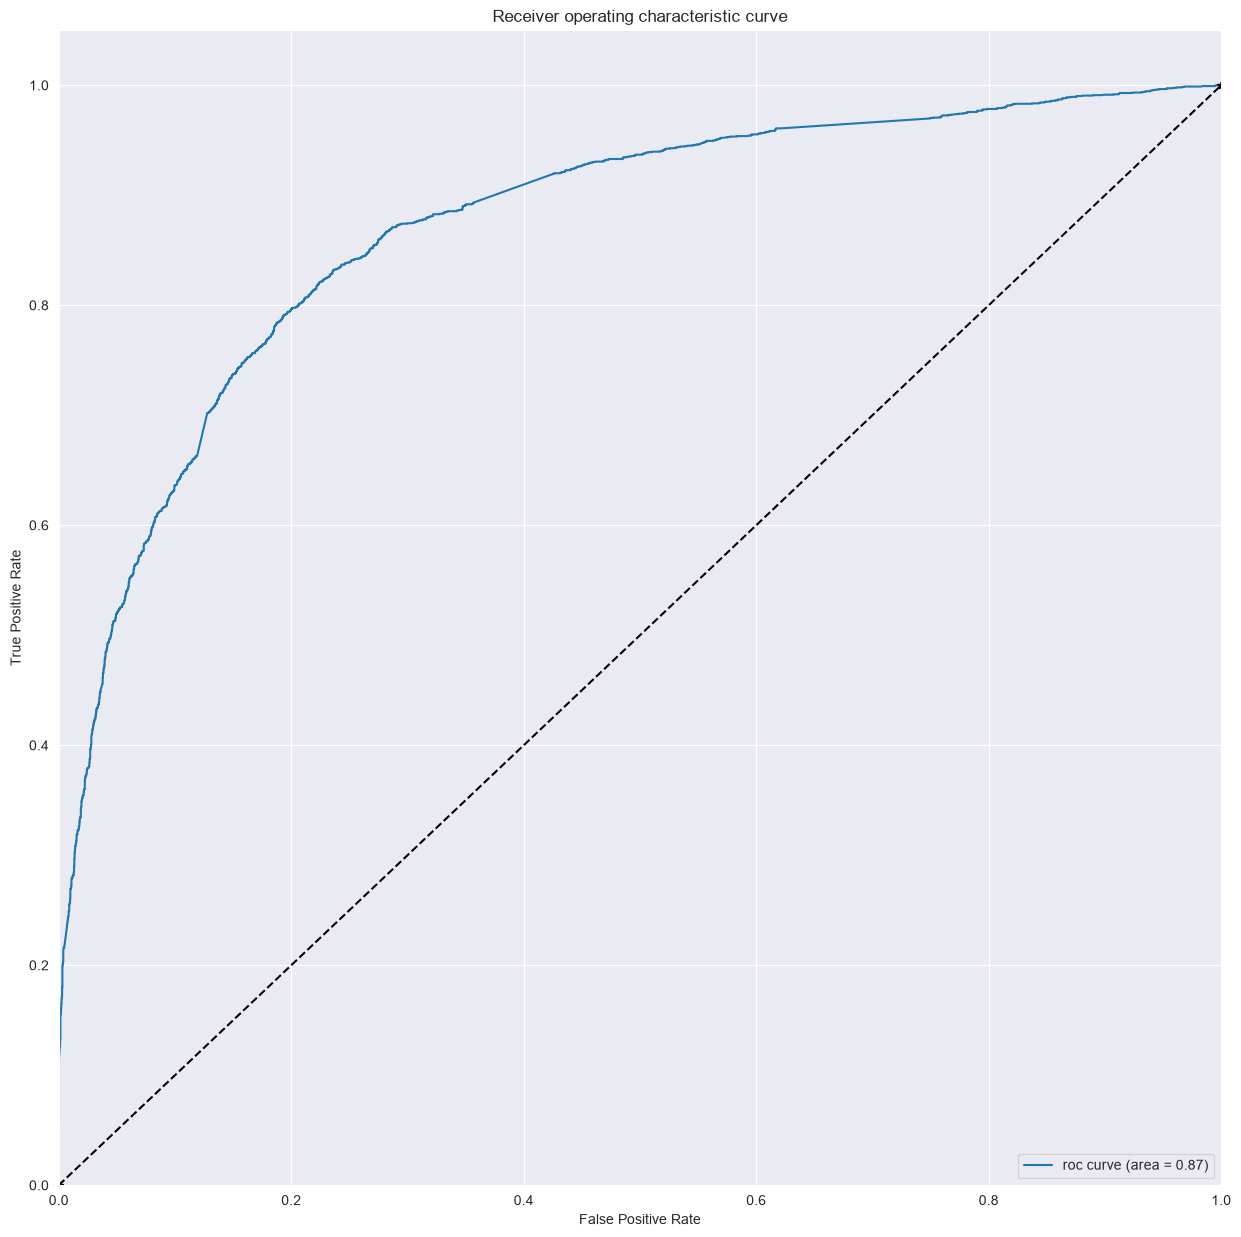

In [231]:
plt.figure(figsize =(15,15))
plt.plot(fpr, tpr, label = 'roc curve (area = %0.2f)'%auc_curve)
plt.plot([0,1], [0,1], 'k*--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic curve')
plt.legend(loc="lower right")
plt.show()


In [ ]:
##finding optimal cutoff pt for 'predicted' column, since 0.5 was choosen arbiterily 

In [235]:
nums = [float(x/10) for x in range(10)]

for num in nums:
    Y_pred_final[num] = Y_pred_final.Converted_probability.map(lambda x : 1 if  x>num  else 0)

In [236]:
Y_pred_final

,Converted,Converted_probability,Lead ID,Predicted,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
3006,1,0.272074,3006,0,1,1,1,0,0,0,0,0,0,0
1259,1,0.187252,1259,0,1,1,0,0,0,0,0,0,0,0
8657,0,0.036739,8657,0,1,0,0,0,0,0,0,0,0,0
6155,0,0.045446,6155,0,1,0,0,0,0,0,0,0,0,0
6962,0,0.289237,6962,0,1,1,1,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5734,0,0.098564,5734,0,1,0,0,0,0,0,0,0,0,0
5191,0,0.096723,5191,0,1,0,0,0,0,0,0,0,0,0
5390,1,0.927019,5390,1,1,1,1,1,1,1,1,1,1,1
860,0,0.159331,860,0,1,1,0,0,0,0,0,0,0,0


In [237]:
probability_cutoff = pd.DataFrame(columns = ['probability','accuracy','sensitivity', 'specifitivity'])


In [238]:
probability_cutoff

,probability,accuracy,sensitivity,specifitivity


In [246]:
for i in nums:
    cm = confusion_matrix(Y_pred_final.Converted, Y_pred_final[i])
    total= sum(sum(cm))
    accuracy = (cm[0,0]+cm[1,1])/total
    sensitivity = cm[1,1]/(cm[1,0]+cm[1,1])
    specifitivity = cm[0,0]/(cm[0,0]+cm[1,1])
    probability_cutoff.loc[i] = [i, accuracy,sensitivity,specifitivity]

probability_cutoff

,probability,accuracy,sensitivity,specifitivity
0.0,0.0,0.383343,1.000000,0.000000
0.1,0.1,0.607486,0.957647,0.395694
0.2,0.2,0.745039,0.886275,0.543987
0.3,0.3,0.787432,0.834902,0.593547
0.4,0.4,0.800511,0.765098,0.633615
0.5,0.5,0.798406,0.656863,0.684617
0.6,0.6,0.791792,0.566667,0.725650
0.7,0.7,0.779765,0.495294,0.756507
0.8,0.8,0.752556,0.399216,0.796644
0.9,0.9,0.711966,0.264706,0.857475


<Axes: xlabel='probability'>

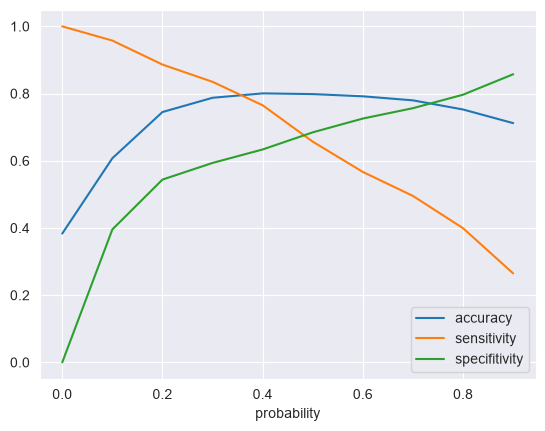

In [248]:
probability_cutoff.plot.line(x='probability', y=['accuracy','sensitivity', 'specifitivity'])

In [ ]:
## we can see the intraction point is 3.75

Y_pred_final['predicted'] = Y_pred_final.Converted_probability.map(lambda x: 1 if x>0.375 else 0)

In [253]:
Y_pred_final['score'] = Y_pred_final.Converted_probability.map(lambda x:round(x*100,2))

In [255]:
Y_pred_final

,Converted,Converted_probability,Lead ID,Predicted,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,predicted,score
3006,1,0.272074,3006,0,1,1,1,0,0,0,0,0,0,0,0,27.21
1259,1,0.187252,1259,0,1,1,0,0,0,0,0,0,0,0,0,18.73
8657,0,0.036739,8657,0,1,0,0,0,0,0,0,0,0,0,0,3.67
6155,0,0.045446,6155,0,1,0,0,0,0,0,0,0,0,0,0,4.54
6962,0,0.289237,6962,0,1,1,1,0,0,0,0,0,0,0,0,28.92
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5734,0,0.098564,5734,0,1,0,0,0,0,0,0,0,0,0,0,9.86
5191,0,0.096723,5191,0,1,0,0,0,0,0,0,0,0,0,0,9.67
5390,1,0.927019,5390,1,1,1,1,1,1,1,1,1,1,1,1,92.70
860,0,0.159331,860,0,1,1,0,0,0,0,0,0,0,0,0,15.93


In [ ]:
####

## Decision Tree

In [256]:
from sklearn.tree import DecisionTreeClassifier

In [258]:
#removing ID since it has no role in training the ML model.
cleaned_leads_dummyfied

,Page Views Per Visit SQRT,TotalVisits SQRT,Prospect ID,Total Time Spent on Website SQRT,Lead Number,Converted,Lead Origin_API,Lead Origin_Landing Page Submission,Lead Origin_Lead Add Form,Lead Origin_Lead Import,...,Last Notable Activity_Form Submitted on Website,Last Notable Activity_Had a Phone Conversation,Last Notable Activity_Modified,Last Notable Activity_Olark Chat Conversation,Last Notable Activity_Page Visited on Website,Last Notable Activity_Resubscribed to emails,Last Notable Activity_SMS Sent,Last Notable Activity_Unreachable,Last Notable Activity_Unsubscribed,Last Notable Activity_View in browser link Clicked
0,0.000000,0.000000,7927b2df-8bba-4d29-b9a2-b6e0beafe620,0.000000,660737,0,1,0,0,0,...,0,0,1,0,0,0,0,0,0,0
1,1.581139,2.236068,2a272436-5132-4136-86fa-dcc88c88f482,25.961510,660728,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1.414214,1.414214,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,39.140772,660727,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1.000000,1.000000,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,17.464249,660719,0,0,1,0,0,...,0,0,1,0,0,0,0,0,0,0
4,1.000000,1.414214,3256f628-e534-4826-9d63-4a8b88782852,37.788887,660681,1,0,1,0,0,...,0,0,1,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9235,1.634013,2.828427,19d6451e-fcd6-407c-b83b-48e1af805ea9,42.953463,579564,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
9236,1.414214,1.414214,82a7005b-7196-4d56-95ce-a79f937a158d,15.427249,579546,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,0
9237,1.414214,1.414214,aac550fe-a586-452d-8d3c-f1b62c94e02c,14.106736,579545,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,0
9238,1.732051,1.732051,5330a7d1-2f2b-4df4-85d6-64ca2f6b95b9,22.338308,579538,1,0,1,0,0,...,0,0,0,0,0,0,1,0,0,0


In [ ]:
cleaned_leads_dummyfied = cleaned_leads_dummyfied.drop('Prospect ID',axis = 1)


In [261]:
X = cleaned_leads_dummyfied.drop('Converted', axis=1)
Y = cleaned_leads_dummyfied['Converted']

In [262]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y,random_state = 42, test_size = 0.28)

In [265]:
print(f'X_train shape {X_train.shape}')

print(f'X_test shape {X_test.shape}')

print(f'Y_train shape {Y_train.shape}')

print(f'Y_test shape {Y_test.shape}')

X_train shape (6652, 154)
X_test shape (2588, 154)
Y_train shape (6652,)
Y_test shape (2588,)


In [269]:
sc = StandardScaler()
X_train_std = sc.fit_transform(X_train.drop('Lead Number', axis=1))

In [270]:
X_train_std

array([[ 1.18901309,  0.73092983,  0.98521466, ..., -0.06501579,
        -0.06264133, -0.01226186],
       [-1.59460627, -1.52442421, -1.24515829, ..., -0.06501579,
        -0.06264133, -0.01226186],
       [-0.34973385, -0.51579922, -0.78797641, ..., -0.06501579,
        -0.06264133, -0.01226186],
       ...,
       [-1.59460627, -1.52442421, -1.24515829, ..., -0.06501579,
        -0.06264133, -0.01226186],
       [ 0.56157601,  0.22256552, -0.27802679, ..., -0.06501579,
        -0.06264133, -0.01226186],
       [-0.34973385, -0.09801307,  1.82936862, ..., -0.06501579,
        -0.06264133, -0.01226186]], shape=(6652, 153))

In [274]:
dt_model = DecisionTreeClassifier(max_depth=5, random_state= 42)
dt_model.fit(X_train_std, Y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

In [280]:
feature_importance = pd.DataFrame({
'feature_name':X_train.drop('Lead Number', axis=1).columns,
'importance':dt_model.feature_importances_
})

In [284]:

feature_importance.sort_values(by = 'importance', ascending = False, inplace = True )
feature_importance

,feature_name,importance
2,Total Time Spent on Website SQRT,0.358997
5,Lead Origin_Lead Add Form,0.254993
149,Last Notable Activity_SMS Sent,0.151139
123,Lead Profile_Potential Lead,0.108725
117,What is your current occupation_Working Profes...,0.049364
...,...,...
144,Last Notable Activity_Had a Phone Conversation,0.000000
142,Last Notable Activity_Email Received,0.000000
141,Last Notable Activity_Email Opened,0.000000
140,Last Notable Activity_Email Marked Spam,0.000000


In [285]:
### evalution metrics

from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, mean_squared_error, mean_absolute_error, median_absolute_error

In [287]:
dt_model.score(X_train_std, Y_train)

0.827720986169573

In [297]:
dt_model_1 = DecisionTreeClassifier(max_depth=7, random_state = 42)
dt_model_1.fit(X_train,Y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",7
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

In [298]:
Y_pred_dt = dt_model_1.predict(X_test)

In [299]:
dt_model_1.score(X_train,Y_train)

0.858538785327721

In [300]:
accuracy_score(Y_test, Y_pred_dt)

0.8438948995363215

In [302]:
Y_pred_proba = dt_model_1.predict_proba(X_test)[:,1]
Y_pred_proba

array([0.09246902, 0.73529412, 0.037704  , ..., 0.9862069 , 0.037704  ,
       0.66304348], shape=(2588,))

In [304]:
from sklearn.metrics import classification_report

In [305]:
# Calculate baseline metrics
print("--- Baseline Model Performance ---")
print(f"Accuracy: {accuracy_score(Y_test, Y_pred_dt):.4f}")
print(f"ROC-AUC: {roc_auc_score(Y_test, Y_pred_proba):.4f}")
print("\nClassification Report:")
print(classification_report(Y_test, Y_pred_dt))

--- Baseline Model Performance ---
Accuracy: 0.8439
ROC-AUC: 0.8956

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.88      0.87      1577
           1       0.81      0.79      0.80      1011

    accuracy                           0.84      2588
   macro avg       0.84      0.83      0.84      2588
weighted avg       0.84      0.84      0.84      2588



# 2. HYPERPARAMETER TUNING (FINE-TUNING) VIA GRID SEARCH

In [321]:
param_grid = {
    'max_depth':[3,5,7,9],
    'min_samples_split':[2, 10, 20],
    'min_samples_leaf':[1,5,10],
    'criterion':['gini','entropy']
}

In [322]:
param_grid

{'max_depth': [3, 5, 7, 9],
 'min_samples_split': [2, 10, 20],
 'min_samples_leaf': [1, 5, 10],
 'criterion': ['gini', 'entropy']}

In [323]:
dt_grid = DecisionTreeClassifier(random_state = 42)


In [324]:
from sklearn.model_selection import GridSearchCV

In [325]:
grid_search = GridSearchCV(
    estimator = dt_grid,
    param_grid = param_grid,
    cv = 5,
    scoring = 'accuracy',
    n_jobs = 1
)

In [326]:
grid_search.fit(X_train, Y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 5, ...], 'min_samples_split': [2, 10, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",Tru

In [327]:
grid_search.best_params_

{'criterion': 'entropy',
 'max_depth': 9,
 'min_samples_leaf': 5,
 'min_samples_split': 20}

In [331]:
best_model = grid_search.best_estimator_

In [332]:
Y_pred_tuned = best_model.predict(X_test)

In [334]:
accuracy_score(Y_test,Y_pred_tuned)

0.8435085007727975

In [343]:
best_features = feature_importance[feature_importance['importance'] > 0]['feature_name']

In [346]:
X_train_new = X_train[best_features]
X_test_new = X_test[best_features]

In [351]:
param_grid = {
    'max_depth' : [3,5,7,10],
    'min_samples_split' : [2,5,10,51,20],
    'min_samples_leaf': [1,3,5,7,10],
    'criterion':['gini','entopy']
}

In [352]:
dt_base_model = DecisionTreeClassifier(random_state = 42)


In [360]:
grid_search = GridSearchCV(
    estimator = dt_base_model,
    param_grid = param_grid,
    cv = 5, ## cross validation it split data into 5 parts and each time it takes 4 parts as training and 1 for validation 
    scoring = 'roc_auc',
    n_jobs = 1
)

In [361]:
grid_search.fit(X_train_new, Y_train)

/Users/srinivasaraodheekonda/Desktop/Data Science/Lead Scoring/lr_venv/lib/python3.12/site-packages/sklearn/model_selection/_validation.py:489: FitFailedWarning: 
500 fits failed out of a total of 1000.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
500 fits failed with the following error:
Traceback (most recent call last):
  File "/Users/srinivasaraodheekonda/Desktop/Data Science/Lead Scoring/lr_venv/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/Users/srinivasaraodheekonda/Desktop/Data Science/Lead Scoring/lr_venv/lib/python3.12/site-packages/sklearn/base.py", line 1393, in wrapper
    estimator._validate_params()
  File "/Us

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entopy'], 'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 3, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,

In [362]:
print(grid_search.best_params_)

{'criterion': 'gini', 'max_depth': 7, 'min_samples_leaf': 5, 'min_samples_split': 20}


In [ ]:
best_dt_model = grid_search.best_estimator_

In [364]:
Y_pred_tuned = best_dt_model.predict(X_test_new)

In [365]:
Y_pred_tuned_proba = best_dt_model.predict_proba(X_test_new)[:, 1]

In [366]:
print("\n--- Tuned Model Performance ---")
print(f"Tuned Accuracy: {accuracy_score(Y_test, Y_pred_tuned):.4f}")
print(f"Tuned ROC-AUC: {roc_auc_score(Y_test, Y_pred_tuned_proba):.4f}")
print("\nOptimized Classification Report:")
print(classification_report(Y_test, Y_pred_tuned))


--- Tuned Model Performance ---
Tuned Accuracy: 0.8377
Tuned ROC-AUC: 0.9005

Optimized Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1577
           1       0.82      0.75      0.78      1011

    accuracy                           0.84      2588
   macro avg       0.83      0.82      0.83      2588
weighted avg       0.84      0.84      0.84      2588



In [376]:
len(Y_train)

6652

In [ ]:


dt_final = pd.DataFrame({"Converted":Y_test.values, "converted_probabiliy":Y_pred_tuned})



In [378]:
y_train_pred = res1.predict(X_train_vif_adj)


Y_pred_final = pd.DataFrame({"Converted":Y_train.values,"Converted_probability":y_train_pred})

Y_pred_final['Lead ID'] = Y_train.index

In [379]:
Y_pred_final

,Converted,Converted_probability,Lead ID
3006,1,0.272074,3006
1259,1,0.187252,1259
8657,0,0.036739,8657
6155,0,0.045446,6155
6962,0,0.289237,6962
...,...,...,...
5734,0,0.098564,5734
5191,0,0.096723,5191
5390,1,0.927019,5390
860,0,0.159331,860


In [370]:
from sklearn.metrics import roc_curve, roc_auc_score, auc


In [450]:
fpr,tpr, threshold = roc_curve(Y_pred_final.Converted,Y_pred_final.Converted_probability, drop_intermediate=False)
auc_curve = roc_auc_score(Y_pred_final.Converted,Y_pred_final.Converted_probability)

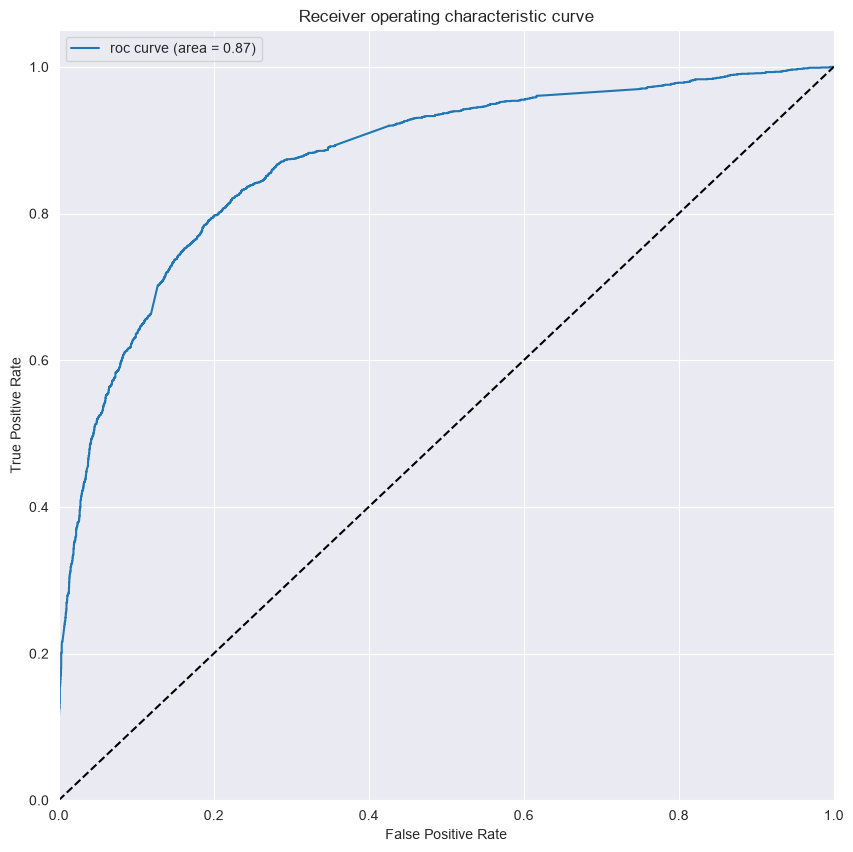

In [451]:
plt.figure(figsize=(10,10))
plt.plot(fpr,tpr, label = "roc curve (area = %0.2f)" %auc_curve)
plt.plot([0,1], [0,1],'k--' )
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic curve')
plt.legend(loc = "upper left")
plt.show()

In [452]:
### finding optimal cut off 

nums = [float(x/10) for x in range(10)]

for num in nums:
    Y_pred_final[num] = Y_pred_final.Converted_probability.map(lambda x : 1 if x>num else 0)


In [453]:
Y_pred_final 

,Converted,Converted_probability,Lead ID,0.9,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8
3006,1,0.272074,3006,0,1,1,1,0,0,0,0,0,0
1259,1,0.187252,1259,0,1,1,0,0,0,0,0,0,0
8657,0,0.036739,8657,0,1,0,0,0,0,0,0,0,0
6155,0,0.045446,6155,0,1,0,0,0,0,0,0,0,0
6962,0,0.289237,6962,0,1,1,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5734,0,0.098564,5734,0,1,0,0,0,0,0,0,0,0
5191,0,0.096723,5191,0,1,0,0,0,0,0,0,0,0
5390,1,0.927019,5390,1,1,1,1,1,1,1,1,1,1
860,0,0.159331,860,0,1,1,0,0,0,0,0,0,0


In [454]:
probability_cutoff = pd.DataFrame(columns = ['Probability','Accuracy','sensitivity', 'specificity'])



In [455]:
nums

[0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

In [456]:

for i in nums:
    cm = confusion_matrix(Y_pred_final.Converted,Y_pred_final[i])
    total=sum(sum(cm))
    Accuracy = (cm[0,0]+cm[1,1])/total
    sensitivity = cm[1,1]/(cm[1,0]+cm[1,1])
    specificity = cm[0,0]/(cm[0,0]+cm[1,1])
    probability_cutoff .loc[i] = [i,Accuracy,sensitivity,specificity]
probability_cutoff


,Probability,Accuracy,sensitivity,specificity
0.0,0.0,0.383343,1.000000,0.000000
0.1,0.1,0.607486,0.957647,0.395694
0.2,0.2,0.745039,0.886275,0.543987
0.3,0.3,0.787432,0.834902,0.593547
0.4,0.4,0.800511,0.765098,0.633615
0.5,0.5,0.798406,0.656863,0.684617
0.6,0.6,0.791792,0.566667,0.725650
0.7,0.7,0.779765,0.495294,0.756507
0.8,0.8,0.752556,0.399216,0.796644
0.9,0.9,0.711966,0.264706,0.857475


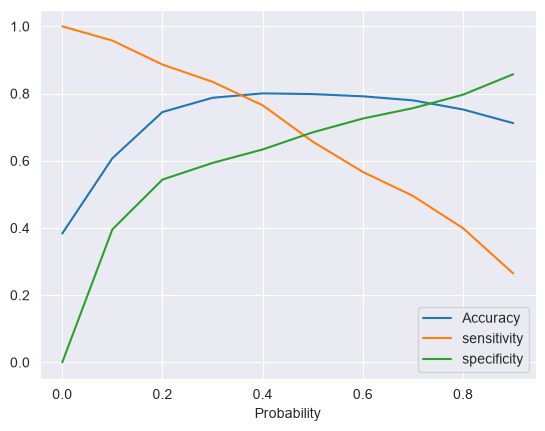

In [459]:
probability_cutoff.plot.line(x='Probability', y=['Accuracy','sensitivity','specificity'])
plt.show()

## RandomForest

In [464]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, cross_val_score


In [ ]:

X

,Page Views Per Visit SQRT,TotalVisits SQRT,Total Time Spent on Website SQRT,Lead Number,Lead Origin_API,Lead Origin_Landing Page Submission,Lead Origin_Lead Add Form,Lead Origin_Lead Import,Lead Origin_Quick Add Form,Lead Source_Click2call,...,Last Notable Activity_Form Submitted on Website,Last Notable Activity_Had a Phone Conversation,Last Notable Activity_Modified,Last Notable Activity_Olark Chat Conversation,Last Notable Activity_Page Visited on Website,Last Notable Activity_Resubscribed to emails,Last Notable Activity_SMS Sent,Last Notable Activity_Unreachable,Last Notable Activity_Unsubscribed,Last Notable Activity_View in browser link Clicked
0,0.000000,0.000000,0.000000,660737,1,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
1,1.581139,2.236068,25.961510,660728,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1.414214,1.414214,39.140772,660727,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1.000000,1.000000,17.464249,660719,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4,1.000000,1.414214,37.788887,660681,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9235,1.634013,2.828427,42.953463,579564,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9236,1.414214,1.414214,15.427249,579546,0,1,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
9237,1.414214,1.414214,14.106736,579545,0,1,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
9238,1.732051,1.732051,22.338308,579538,0,1,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0


In [466]:
X_train

,Page Views Per Visit SQRT,TotalVisits SQRT,Total Time Spent on Website SQRT,Lead Number,Lead Origin_API,Lead Origin_Landing Page Submission,Lead Origin_Lead Add Form,Lead Origin_Lead Import,Lead Origin_Quick Add Form,Lead Source_Click2call,...,Last Notable Activity_Form Submitted on Website,Last Notable Activity_Had a Phone Conversation,Last Notable Activity_Modified,Last Notable Activity_Olark Chat Conversation,Last Notable Activity_Page Visited on Website,Last Notable Activity_Resubscribed to emails,Last Notable Activity_SMS Sent,Last Notable Activity_Unreachable,Last Notable Activity_Unsubscribed,Last Notable Activity_View in browser link Clicked
3006,2.236068,2.236068,30.854497,630972,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
1259,0.000000,0.000000,0.000000,646546,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8657,1.000000,1.000000,6.324555,583688,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
6155,2.000000,2.000000,11.269428,602565,1,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
6962,1.153256,2.000000,27.422618,596233,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5734,1.732051,1.732051,11.401754,605829,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5191,0.000000,0.000000,0.000000,610099,1,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
5390,0.000000,0.000000,0.000000,608489,0,0,1,0,0,0,...,0,0,0,0,0,0,1,0,0,0
860,1.732051,1.732051,13.379088,651374,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [474]:
random_search = {
    'max_depth':[3,5,8,10,14,17,20],
    'min_samples_leaf':[4,6,8,12,14],
    'min_samples_split':[5,7,9,11],
    'criterion':['entropy','gini'],
    'n_estimators':[300,200,250,400]
}

In [475]:
clf = RandomForestClassifier()

In [469]:
clf.fit(X_train,Y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [476]:
model = RandomizedSearchCV(estimator = clf, param_distributions =random_search, n_iter = 10, cv = 4, random_state = 101, n_jobs=1  )

model.fit(X_train,Y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestClassifier()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'criterion': ['entropy', 'gini'], 'max_depth': [3, 5, ...], 'min_samples_leaf': [4, 6, ...], 'min_samples_split': [5, 7, ...], ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",4
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",101
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple

In [ ]:
print(model.best_params_)


{'n_estimators': 200, 'min_samples_split': 11, 'min_samples_leaf': 4, 'max_depth': 17, 'criterion': 'gini'}


In [480]:
best_model = model.best_estimator_
best_model

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",17
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",11
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",4
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(

In [490]:
Y_pred_rf = best_model.predict(X_train)

In [511]:
best_model.score(X_train,Y_train)

0.8816897173782321

In [510]:
accuracy_score(Y_pred_rf,Y_train)

0.8816897173782321

In [522]:
y_train_pred_rf = best_model.predict_proba(X_train)[:, 1]

In [537]:
Y_pred_final_rf = pd.DataFrame({
    "Converted":Y_train,
    "Converted_probability":y_train_pred_rf
    
    })

In [538]:
Y_pred_final_rf

,Converted,Converted_probability
3006,1,0.542622
1259,1,0.437392
8657,0,0.124802
6155,0,0.096913
6962,0,0.324184
...,...,...
5734,0,0.128028
5191,0,0.022244
5390,1,0.915477
860,0,0.191550


In [539]:
Y_pred_final_rf['Lead ID'] = Y_train.index

In [540]:

Y_pred_final_rf['Predicted'] = Y_pred_final_rf.Converted_probability.map(lambda x: 1 if x>0.5 else 0)


In [541]:
Y_pred_final_rf

,Converted,Converted_probability,Lead ID,Predicted
3006,1,0.542622,3006,1
1259,1,0.437392,1259,0
8657,0,0.124802,8657,0
6155,0,0.096913,6155,0
6962,0,0.324184,6962,0
...,...,...,...,...
5734,0,0.128028,5734,0
5191,0,0.022244,5191,0
5390,1,0.915477,5390,1
860,0,0.191550,860,0


In [542]:
fpr, tpr, thresholds = roc_curve(Y_pred_final_rf.Converted, Y_pred_final_rf.Converted_probability, drop_intermediate=False)
auc_curve = roc_auc_score(Y_pred_final_rf.Converted, Y_pred_final_rf.Converted_probability,)


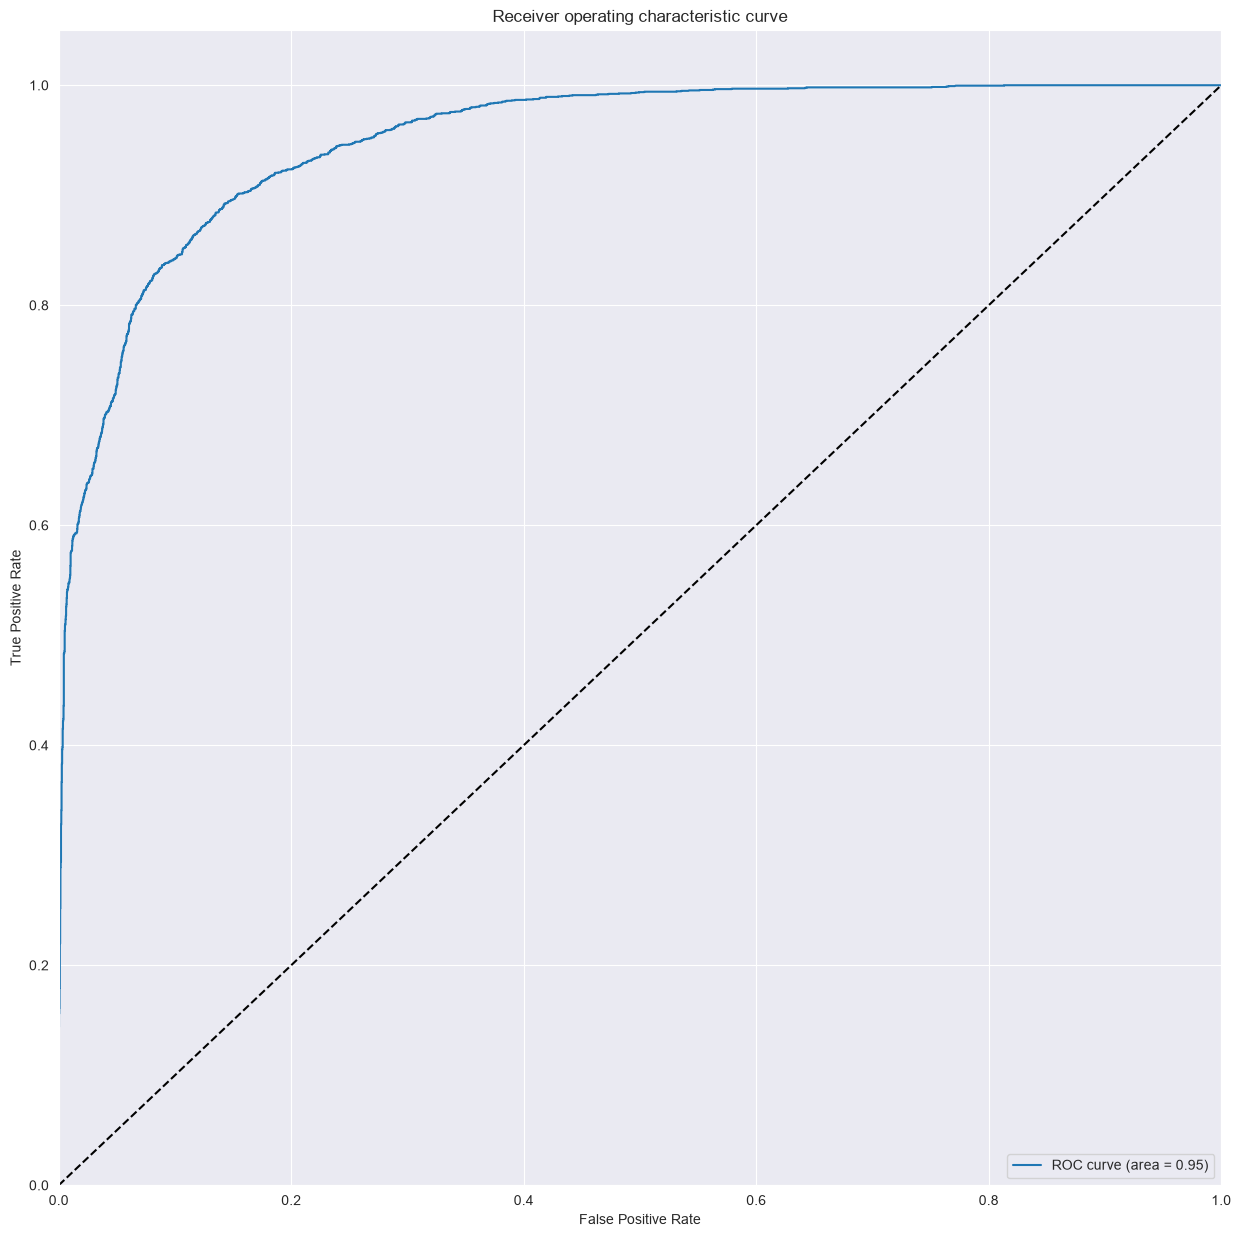

In [543]:
plt.figure(figsize=(15,15))
plt.plot(fpr,tpr, label = 'ROC curve (area = %0.2f)'%auc_curve)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic curve')
plt.legend(loc="lower right")
plt.show()


In [ ]:
## finding optimal cut off for predicted column since 0.5 was choosen arbitarly


In [544]:
nums = [float(x/10) for x in range(10)]
for num in nums:
    Y_pred_final_rf[num] = Y_pred_final_rf.Converted_probability.map(lambda x : 1 if x>num else 0 )

In [545]:
Y_pred_final_rf

,Converted,Converted_probability,Lead ID,Predicted,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
3006,1,0.542622,3006,1,1,1,1,1,1,1,0,0,0,0
1259,1,0.437392,1259,0,1,1,1,1,1,0,0,0,0,0
8657,0,0.124802,8657,0,1,1,0,0,0,0,0,0,0,0
6155,0,0.096913,6155,0,1,0,0,0,0,0,0,0,0,0
6962,0,0.324184,6962,0,1,1,1,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5734,0,0.128028,5734,0,1,1,0,0,0,0,0,0,0,0
5191,0,0.022244,5191,0,1,0,0,0,0,0,0,0,0,0
5390,1,0.915477,5390,1,1,1,1,1,1,1,1,1,1,1
860,0,0.191550,860,0,1,1,0,0,0,0,0,0,0,0


In [549]:
### creating probability cutoff 

probability_cutoff_rf = pd.DataFrame(columns = ['probability','accuracy', 'sensitivity','specificity' ])
probability_cutoff_rf

,probability,accuracy,sensitivity,specificity


In [573]:
for i in nums:
    cm = confusion_matrix(Y_pred_final_rf.Converted,Y_pred_final_rf[i])
    total= sum(sum(cm))
    accuracy = (cm[0,0]+cm[1,1])/total
    sensitivity = (cm[1,1]/(cm[1,0]+cm[1,1]))    
    specificity = (cm[0,0]/(cm[0,0]+cm[1,1]))
    probability_cutoff_rf.loc[i]=[i,accuracy,sensitivity,specificity]
probability_cutoff_rf

,probability,accuracy,sensitivity,specificity
0.0,0.0,0.383343,1.000000,0.000000
0.1,0.1,0.610042,0.997255,0.373337
0.2,0.2,0.778112,0.976078,0.519127
0.3,0.3,0.832532,0.940784,0.566811
0.4,0.4,0.871918,0.882745,0.611897
0.5,0.5,0.881690,0.796078,0.653879
0.6,0.6,0.855683,0.681961,0.694483
0.7,0.7,0.824414,0.558039,0.740518
0.8,0.8,0.766687,0.396471,0.801765
0.9,0.9,0.678142,0.161176,0.908889


<Axes: xlabel='probability'>

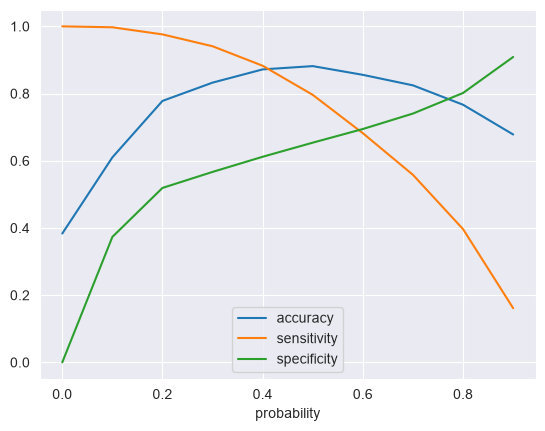

In [574]:
probability_cutoff_rf.plot.line(x='probability',y=['accuracy','sensitivity','specificity'])

In [576]:
final_model = Y_pred_final_rf[['Lead ID','Converted','Converted_probability']]

In [577]:
final_model['Predicted'] = final_model.Converted_probability.map(lambda x: 1 if x>0.47 else 0)

/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T/ipykernel_63411/2691775235.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_model['Predicted'] = final_model.Converted_probability.map(lambda x: 1 if x>0.47 else 0)


In [578]:
final_model

,Lead ID,Converted,Converted_probability,Predicted
3006,3006,1,0.542622,1
1259,1259,1,0.437392,0
8657,8657,0,0.124802,0
6155,6155,0,0.096913,0
6962,6962,0,0.324184,0
...,...,...,...,...
5734,5734,0,0.128028,0
5191,5191,0,0.022244,0
5390,5390,1,0.915477,1
860,860,0,0.191550,0


In [582]:
final_model.to_csv('LeadScoring.csv')

In [ ]:
import pickle


In [587]:
pip install shap

Note: you may need to restart the kernel to use updated packages.


## XGBoost Classifier

In [ ]:
from sklearn.ensemble import 

In [592]:
X_train

,Page Views Per Visit SQRT,TotalVisits SQRT,Total Time Spent on Website SQRT,Lead Number,Lead Origin_API,Lead Origin_Landing Page Submission,Lead Origin_Lead Add Form,Lead Origin_Lead Import,Lead Origin_Quick Add Form,Lead Source_Click2call,...,Last Notable Activity_Form Submitted on Website,Last Notable Activity_Had a Phone Conversation,Last Notable Activity_Modified,Last Notable Activity_Olark Chat Conversation,Last Notable Activity_Page Visited on Website,Last Notable Activity_Resubscribed to emails,Last Notable Activity_SMS Sent,Last Notable Activity_Unreachable,Last Notable Activity_Unsubscribed,Last Notable Activity_View in browser link Clicked
3006,2.236068,2.236068,30.854497,630972,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
1259,0.000000,0.000000,0.000000,646546,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8657,1.000000,1.000000,6.324555,583688,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
6155,2.000000,2.000000,11.269428,602565,1,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
6962,1.153256,2.000000,27.422618,596233,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5734,1.732051,1.732051,11.401754,605829,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5191,0.000000,0.000000,0.000000,610099,1,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
5390,0.000000,0.000000,0.000000,608489,0,0,1,0,0,0,...,0,0,0,0,0,0,1,0,0,0
860,1.732051,1.732051,13.379088,651374,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [593]:
X_test

,Page Views Per Visit SQRT,TotalVisits SQRT,Total Time Spent on Website SQRT,Lead Number,Lead Origin_API,Lead Origin_Landing Page Submission,Lead Origin_Lead Add Form,Lead Origin_Lead Import,Lead Origin_Quick Add Form,Lead Source_Click2call,...,Last Notable Activity_Form Submitted on Website,Last Notable Activity_Had a Phone Conversation,Last Notable Activity_Modified,Last Notable Activity_Olark Chat Conversation,Last Notable Activity_Page Visited on Website,Last Notable Activity_Resubscribed to emails,Last Notable Activity_SMS Sent,Last Notable Activity_Unreachable,Last Notable Activity_Unsubscribed,Last Notable Activity_View in browser link Clicked
4608,1.634013,2.828427,15.874508,615582,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7935,1.414214,1.414214,30.479501,588939,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4043,1.000000,1.000000,1.414214,621242,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
7821,1.414214,1.414214,17.972201,589803,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
856,1.732051,1.732051,14.177447,651441,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8034,2.080865,3.605551,30.886890,588188,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
8303,1.732051,1.732051,7.937254,586447,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
2549,1.414214,1.414214,29.274562,635012,1,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
5130,0.000000,0.000000,0.000000,610648,1,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0


In [601]:
import optuna
import xgboost as xgb
from sklearn.model_selection import RandomizedSearchCV

In [602]:
param_grid = {
    'max_depth':[3,5,7,10,13,15,17,19],
    'learning_rate':[0.01,0.05,0.07,0.1,0.2],
    'n_estimators':[100,500,700,200,250,300],
    'subsamples':[0.5,0.7,0.8,0.6],
    "colsample_bytree": [0.5, 0.7, 1.0]


}

In [605]:
xg_boost_cls = xgb.XGBClassifier(eval_metrics = 'logloss')

In [606]:
model = RandomizedSearchCV(
    estimator=xg_boost_cls,
    param_distributions=param_grid,
    n_iter=50,
    scoring='accuracy',
    cv = 3,
    verbose=1,
    n_jobs=1

)

In [607]:
model.fit(X_train,Y_train)

Fitting 3 folds for each of 50 candidates, totalling 150 fits


/Users/srinivasaraodheekonda/Desktop/Data Science/Lead Scoring/lr_venv/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [00:09:21] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:793: 
Parameters: { "eval_metrics", "subsamples" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/Users/srinivasaraodheekonda/Desktop/Data Science/Lead Scoring/lr_venv/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [00:09:21] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:793: 
Parameters: { "eval_metrics", "subsamples" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/Users/srinivasaraodheekonda/Desktop/Data Science/Lead Scoring/lr_venv/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [00:09:22] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:793: 
Parameters: { "eval_metrics", "subsamples" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/Users/srinivasaraodheekonda/Desktop/Data Scie

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...obs=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.5, 0.7, ...], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 5, ...], 'n_estimators': [100, 500, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and p

In [608]:
model.best_params_

{'subsamples': 0.6,
 'n_estimators': 250,
 'max_depth': 5,
 'learning_rate': 0.1,
 'colsample_bytree': 0.7}

In [609]:
model.best_score_

np.float64(0.8526757673137825)

In [613]:
predicted_probability = model.predict_proba(X_train)[:,1]

In [626]:
Y_train

3006    1
1259    1
8657    0
6155    0
6962    0
       ..
5734    0
5191    0
5390    1
860     0
7270    1
Name: Converted, Length: 6652, dtype: int64

In [630]:
y_pred_final_xg = pd.DataFrame({
    "Converted":Y_train,
    "predicted_probability": predicted_probability,
    'Lead Number':X_train['Lead Number']
})

In [636]:
y_pred_final_xg

,Converted,predicted_probability,Lead Number
3006,1,0.661687,630972
1259,1,0.578324,646546
8657,0,0.096984,583688
6155,0,0.032831,602565
6962,0,0.173907,596233
...,...,...,...
5734,0,0.053796,605829
5191,0,0.007855,610099
5390,1,0.962270,608489
860,0,0.168963,651374


In [641]:
fpr, tpr, threshold = roc_curve(y_pred_final_xg.Converted,y_pred_final_xg.predicted_probability ,drop_intermediate = False)
auc_curve = roc_auc_score(y_pred_final_xg.Converted,y_pred_final_xg.predicted_probability)

In [648]:
auc_curve

0.9705880440913567

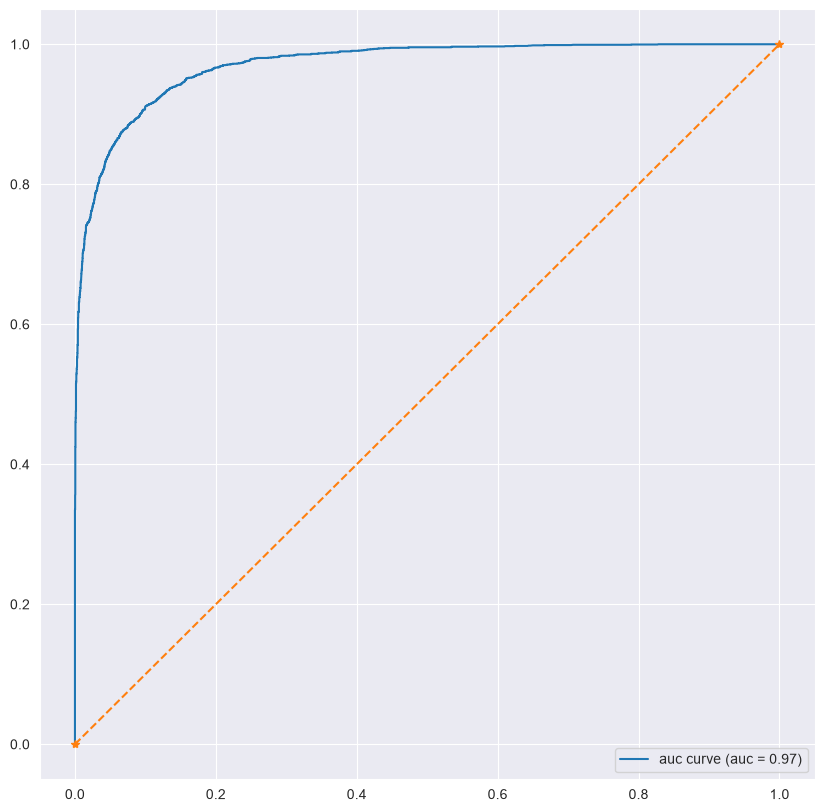

In [652]:
plt.figure(figsize = (10,10))
plt.plot(fpr, tpr, label = 'auc curve (auc = %0.02f)'%auc_curve)
plt.legend(loc = 'lower right')
plt.plot([0,1],[0,1], '*--')

In [ ]:
### Gradiant Boosting 

# Gradiant Boosting 

In [653]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, classification_report

3006    1
1259    1
8657    0
6155    0
6962    0
       ..
5734    0
5191    0
5390    1
860     0
7270    1
Name: Converted, Length: 6652, dtype: int64

In [657]:
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth = 3,
    random_state = 42
)

In [658]:
gb_model.fit(X_train,Y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [659]:
Y_pred = gb_model.predict(X_test)

In [660]:
gb_model.score(X_train,Y_train)

0.8603427540589297

In [661]:
gb_model.score(X_test,Y_test)

0.8581916537867079

In [663]:
accuracy_score(Y_test,Y_pred)

0.8581916537867079

In [664]:
confusion_matrix(Y_test,Y_pred)

array([[1399,  178],
       [ 189,  822]])

In [667]:
classification_report(Y_test,Y_pred)

'              precision    recall  f1-score   support\n\n           0       0.88      0.89      0.88      1577\n           1       0.82      0.81      0.82      1011\n\n    accuracy                           0.86      2588\n   macro avg       0.85      0.85      0.85      2588\nweighted avg       0.86      0.86      0.86      2588\n'

In [678]:
pred_prob = gb_model.predict_proba(X_test)[0:,1]

In [679]:
predict_prob = pd.DataFrame({
    "Converted":Y_test,
    "pred_prob":pred_prob
})

In [680]:
predict_prob

,Converted,pred_prob
4608,1,0.122754
7935,0,0.141576
4043,0,0.021503
7821,0,0.481643
856,0,0.043238
...,...,...
8034,1,0.509758
8303,0,0.035107
2549,1,0.967232
5130,0,0.055357


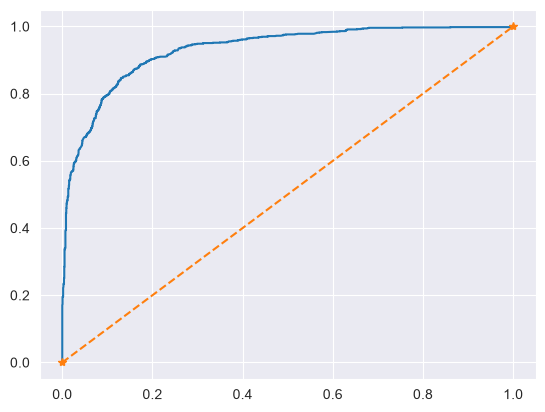

In [694]:
fpr, tpr, threshold = roc_curve(predict_prob.Converted, predict_prob.pred_prob)
plt.plot(fpr, tpr)
plt.plot([0,1],[0,1],'*--')


In [708]:
param_grid_gb = {
    'max_depth':[3,5,7],
    'learning_rate':[0.07,0.1],
    'n_estimators':[100,150, 200],
    'min_samples_split':[2,8,12]
}

In [705]:
model_gb = GradientBoostingClassifier(random_state=42)

In [711]:
grid_search_gb = RandomizedSearchCV(
    estimator = model_gb,
    param_distributions = param_grid_gb,
    cv=5,
    scoring = 'roc_auc',
    n_jobs = 1,
    n_iter = 3


)

In [712]:
grid_search_gb.fit(X_train, Y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GradientBoost...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'learning_rate': [0.07, 0.1], 'max_depth': [3, 5, ...], 'min_samples_split': [2, 8, ...], 'n_estimators': [100, 150, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",3
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selec

In [713]:
grid_search_gb.best_params_

{'n_estimators': 200,
 'min_samples_split': 12,
 'max_depth': 5,
 'learning_rate': 0.07}

In [714]:
grid_search_gb.best_score_

np.float64(0.9242673396978291)

In [715]:
grid_search_gb.best_estimator_

,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.07
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",200
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",12
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (

In [716]:
final_gb_model = grid_search_gb.best_estimator_

In [744]:
Y_pred = final_gb_model.predict(X_train)
Y_pred_probability = final_gb_model.predict_proba(X_train)[0:,1]

In [745]:
Y_pred_probability

array([0.64021429, 0.53221376, 0.06329519, ..., 0.97294366, 0.15357014,
       0.6607855 ], shape=(6652,))

In [746]:
final_gb_model.score(X_train,Y_train)

0.9061936259771497

In [747]:
final_gb_model.score(X_test,Y_test)

0.8612828438948995

In [748]:
    optimal_cutoff = pd.DataFrame({
        "converted":Y_train,
        "Converted_probability":Y_pred_probability,
        "Lead Number":X_train['Lead Number']

        
    })

In [749]:
optimal_cutoff

,converted,Converted_probability,Lead Number
3006,1,0.640214,630972
1259,1,0.532214,646546
8657,0,0.063295,583688
6155,0,0.043164,602565
6962,0,0.322986,596233
...,...,...,...
5734,0,0.076739,605829
5191,0,0.016421,610099
5390,1,0.972944,608489
860,0,0.153570,651374


In [750]:
accuracy_score(Y_train,Y_pred)

0.9061936259771497

In [751]:
### as in the model it take optimal cutoff

nums = [float(x/10) for x in range(10)]
nums

[0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

In [753]:
for i in nums:
    optimal_cutoff[i] = optimal_cutoff.Converted_probability.map(lambda X: 1 if X>i else 0)
    

In [754]:
optimal_cutoff

,converted,Converted_probability,Lead Number,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
3006,1,0.640214,630972,1,1,1,1,1,1,1,0,0,0
1259,1,0.532214,646546,1,1,1,1,1,1,0,0,0,0
8657,0,0.063295,583688,1,0,0,0,0,0,0,0,0,0
6155,0,0.043164,602565,1,0,0,0,0,0,0,0,0,0
6962,0,0.322986,596233,1,1,1,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5734,0,0.076739,605829,1,0,0,0,0,0,0,0,0,0
5191,0,0.016421,610099,1,0,0,0,0,0,0,0,0,0
5390,1,0.972944,608489,1,1,1,1,1,1,1,1,1,1
860,0,0.153570,651374,1,1,0,0,0,0,0,0,0,0


In [755]:
Prob = pd.DataFrame(columns=['probability', 'accuracy', 'sensitivity','specificity'])
Prob

,probability,accuracy,sensitivity,specificity


In [756]:
for i in nums:
    cm = confusion_matrix(optimal_cutoff.converted,optimal_cutoff[i] )
    total=sum(sum(cm))
    accuracy = (cm[1,1]+cm[0,0])/total
    sensitivity = cm[1,1]/(cm[1,1]+cm[1,0])
    specificity = cm[0,0]/(cm[0,0]+cm[1,1])
    Prob.loc[i] = [i,accuracy, sensitivity, specificity]


In [757]:
Prob

,probability,accuracy,sensitivity,specificity
0.0,0.0,0.383343,1.000000,0.000000
0.1,0.1,0.768641,0.987059,0.507725
0.2,0.2,0.852225,0.962353,0.567119
0.3,0.3,0.884396,0.922745,0.600034
0.4,0.4,0.895971,0.885098,0.621309
0.5,0.5,0.906194,0.854510,0.638520
0.6,0.6,0.902135,0.805882,0.657557
0.7,0.7,0.883794,0.729804,0.683450
0.8,0.8,0.844859,0.607843,0.724199
0.9,0.9,0.789838,0.453725,0.779787


<Figure size 1000x1000 with 0 Axes>

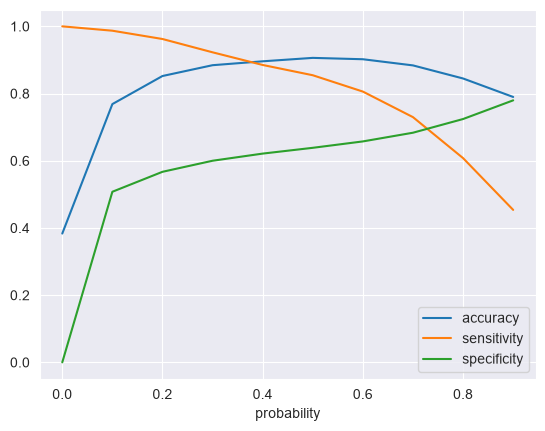

In [758]:
plt.figure(figsize=(10,10))
Prob.plot.line(x = 'probability', y=['accuracy','sensitivity','specificity'])
plt.show()